# Plasticity plotting

This notebook generates plots to visualize neural plasticity post-patching by comparing outputs of a model finetuned using baseline data for baseline and post-patching data. The inference data is expected to exist under settings.INFERENCE_DIR, organized by model name and fold. The notebook allows you to specify which subjects and conditions to visualize.

In [1]:
import os

import numpy as np
from core import plotting
from core import io
from core import settings
from core import utils
import matplotlib.pyplot as plt
from scipy.stats import sem, ttest_rel, wilcoxon
import mne
from core import plot_data_processing as data_processor

In [2]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

model_name = "masking_10_19"
subjects = None # set to None to load all subjects
conditions = ["global"]  # set to None to load all conditions
id_low, id_high = None, None
trial_ids = [i for i in range(id_low, id_high)] if id_low is not None and id_high is not None else None #[]  # set to None to load all trial ids
bands = None #[] # set to None to visualize all frequency bands
exclude_left_patched = True
exclude_right_patched_lefties = True # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False # set to True to exclude button press trials (everything before STMD59)
time_window = "analysis" # set which time window to analyze, options are "analysis" and "full"
topomap_vlim = None # colour scale of the effect-size topomaps: None = one symmetric scale per figure from its largest |value|, a number (e.g. 0.5) = the same fixed scale in all topomap figures


In [3]:
# select appropriate frequency bands based on user input
if bands is None:
    bands = list(settings.FREQ_BANDS.keys())
else:
    loaded = []
    for band in bands:
        for key in settings.FREQ_BANDS.keys():
            if band in key:
                loaded.append(key)
    bands = loaded

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT/"eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT/"rightpatch_eye_dominance.csv")) # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)
    print(exclude_subjects)

an_suffix = "window"
if time_window == "analysis":
    an_suffix+= "_analysis"
elif time_window == "full":
    an_suffix+= "_full"

excl_suffix = "excl"
if exclude_left_patched:
    excl_suffix+= "_left"
if exclude_right_patched_lefties:
    excl_suffix+= "_rightlefties"
if exclude_button_press:
    excl_suffix+= "_buttonpress"
if excl_suffix == "excl":
    excl_suffix = ""

# every plot of this notebook is saved under {model_name}/{conditions}/{plot type}/
plot_root = settings.PLOT_INFERENCE / model_name / ("_".join(conditions) if conditions else "all_conditions")

if trial_ids is not None:
    plot_root = plot_root / f"trial_{id_low}-{id_high}"


### Filter the inference data to only include the specified subjects, conditions, and trial ids

In [4]:
def load_filtered_merged(stim_patch: str):
    baseline_merged = []
    postpatch_merged = []

    for i in range(1, 7):
        b_file_path = settings.INFERENCE_DIR / model_name / str(i) / "baseline_reconstruction.h5"
        p_file_path = settings.INFERENCE_DIR / model_name / str(i) / "postpatch_reconstruction.h5"

        b_fold_trials = io.load_inference_trials(b_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window=time_window, stim_patch=stim_patch)
        baseline_merged.extend(b_fold_trials)
        p_fold_trials = io.load_inference_trials(p_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window=time_window, stim_patch=stim_patch)
        postpatch_merged.extend(p_fold_trials)
    return baseline_merged, postpatch_merged

baseline_merged, postpatch_merged = load_filtered_merged("post")
baseline_merged_pre, postpatch_merged_pre = load_filtered_merged("pre")


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filteri

### Power-corrected MAE
In dB, a channel's error shrinks when its power rises with a component the model predicts, and grows when its power falls (see the injection test), so a change in power shows up as a change in MAE. `fill_corrected_maes` removes that dependence:
power level (`signal_mean`, the mean dB of the target) and MAE are centered within each subject and session, one line per band is fitted on the centered trials of all subjects, and every trial's MAE is corrected to the mean baseline power:
`corrected MAE = MAE - slope * (power - mean baseline power)`.
It runs separately for the post- and the pre-stimulus patch, and the whole tensor and every channel are corrected separately (own slopes and reference power). The results are stored in `corrected_mae` / `corrected_mae_bandwise` of `trial.metrics` and `trial.channel_metrics`.

In [5]:
slopes, channel_slopes = data_processor.fill_corrected_maes(baseline_merged, postpatch_merged, bands)

slopes_pre, channel_slopes_pre = data_processor.fill_corrected_maes(baseline_merged_pre, postpatch_merged_pre, bands)

print("Global slopes (MAE per dB of power) and the range of the channel slopes:")
for patch, (patch_slopes, patch_channel_slopes) in {"post-stimulus": (slopes, channel_slopes), "pre-stimulus": (slopes_pre, channel_slopes_pre)}.items():
    print(patch)
    for band, slope in patch_slopes.items():
        ch_values = [patch_channel_slopes[ch][band] for ch in patch_channel_slopes]
        print(f"  {band:16s} {slope:.3f}   channel slopes: {np.nanmin(ch_values):.3f} - {np.nanmax(ch_values):.3f}")


Global slopes (MAE per dB of power) and the range of the channel slopes:
post-stimulus
  all bands        -0.029   channel slopes: -0.096 - -0.001
  theta (5-8Hz)    -0.104   channel slopes: -0.197 - -0.084
  alpha (8-12Hz)   -0.102   channel slopes: -0.189 - -0.118
  beta (12-30Hz)   -0.015   channel slopes: -0.123 - 0.002
  gamma (30-60Hz)  0.026   channel slopes: -0.040 - 0.039
pre-stimulus
  all bands        -0.015   channel slopes: -0.082 - -0.003
  theta (5-8Hz)    -0.085   channel slopes: -0.200 - -0.111
  alpha (8-12Hz)   -0.092   channel slopes: -0.185 - -0.125
  beta (12-30Hz)   -0.016   channel slopes: -0.099 - -0.004
  gamma (30-60Hz)  0.027   channel slopes: -0.073 - 0.036


# Plotting the difference between baseline and post-patching performance

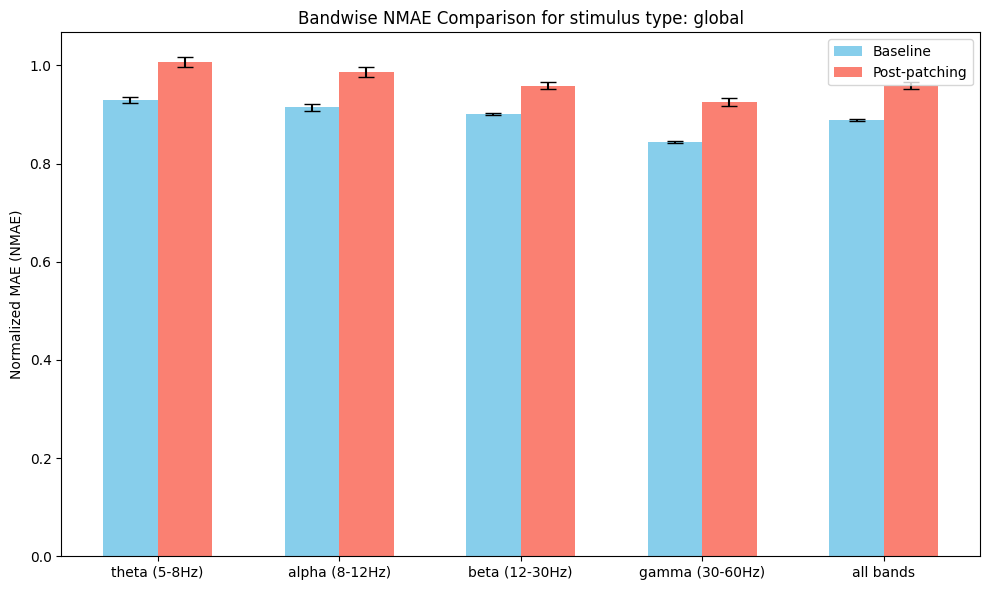

In [6]:



baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="nmae", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="nmae", bands=settings.FREQ_BANDS)

title = f'Bandwise NMAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels, title=title)
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_comparison", default_name=f"error_{an_suffix}_{excl_suffix}")


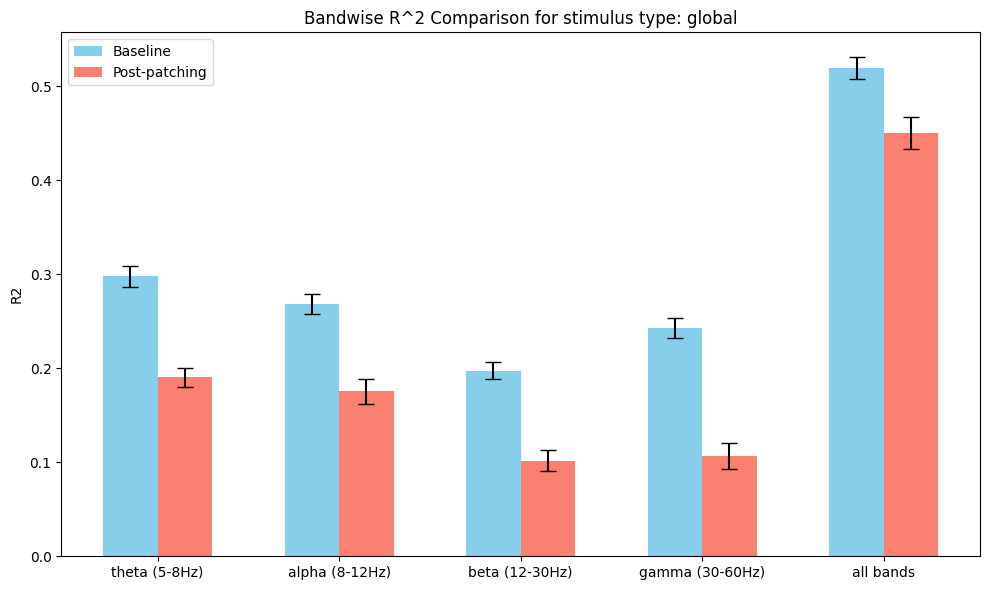

In [7]:


baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)

title = f'Bandwise R^2 Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
y_label = "R2"

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels, title=title, y_label=y_label)
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_comparison", default_name=f"r2_error_{an_suffix}_{excl_suffix}")


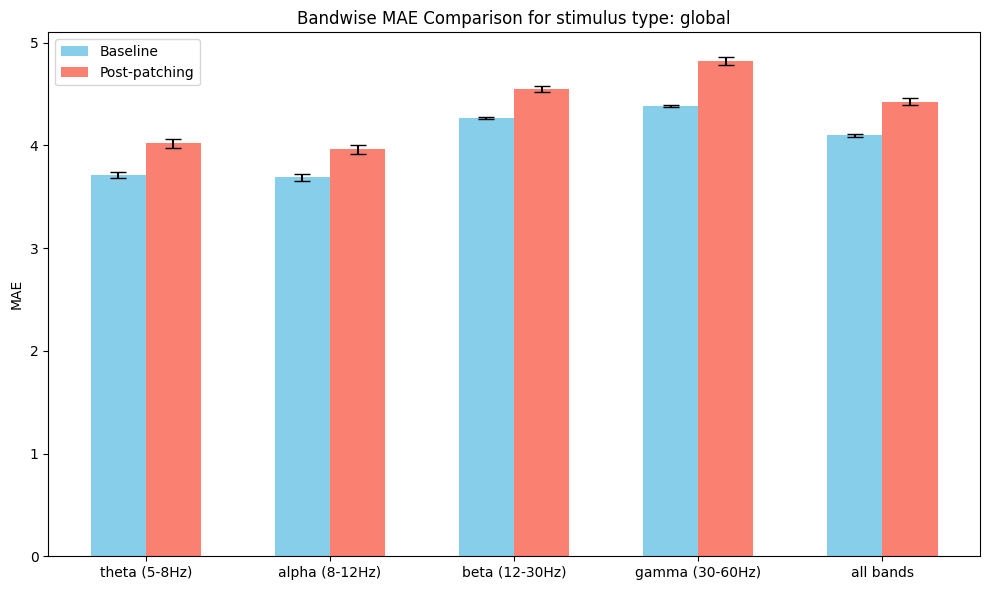

In [8]:
# Plotting the difference between baseline and post-patching performance


baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged,
                                                                           metric_name="mae_bandwise",
                                                                           bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged,
                                                                              metric_name="mae_bandwise",
                                                                              bands=settings.FREQ_BANDS)

title = f'Bandwise MAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
ylabel = "MAE"
ylim = None

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels,
                                    title=title, y_label=ylabel, ylim=ylim)

plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison",
                     default_name=f"error_{an_suffix}_{excl_suffix}")

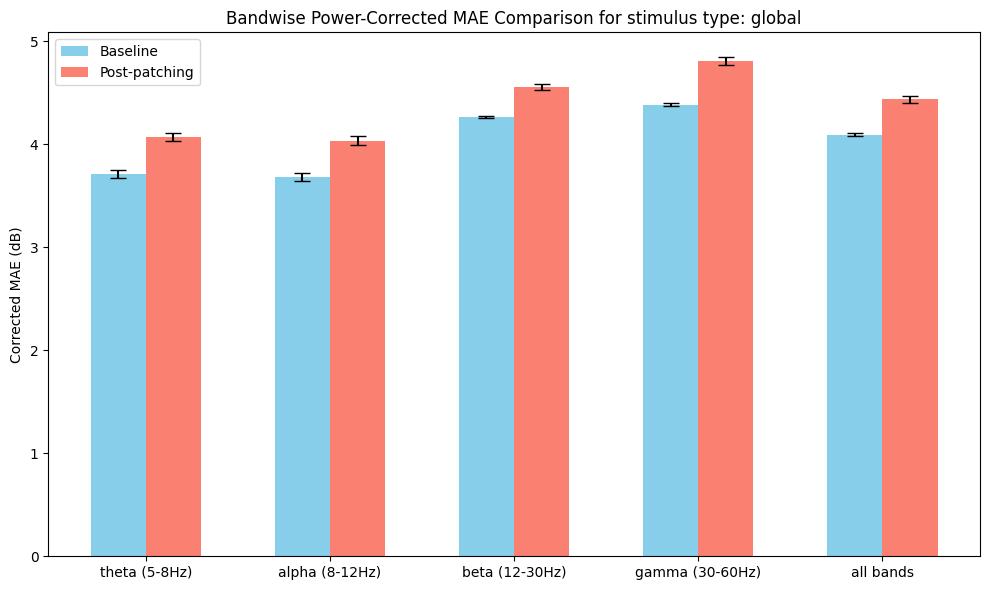

In [9]:
# power-corrected MAE of the post-stimulus patch (trial level, see fill_corrected_maes above)
baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="corrected_mae_bandwise", bands=bands)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="corrected_mae_bandwise", bands=bands)

title = f'Bandwise Power-Corrected MAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
ylabel = "Corrected MAE (dB)"

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels,
                                    title=title, y_label=ylabel)

plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison",
                     default_name=f"corrected_error_{an_suffix}_{excl_suffix}")


## Single channel comparison viewer

In [10]:
input_metrics = []

input_metrics.append(data_processor.get_channel_viewer_metrics(baseline_merged, []))  # metadata only, the viewer computes the errors of the shown window
input_metrics.append(data_processor.get_channel_viewer_metrics(postpatch_merged, []))

In [11]:

input_data = [baseline_merged, postpatch_merged]
styling_params = {
        "param_text": "",
        #"suptitle": f"Single channel reconstruction comparison for stimulus type: {', '.join(conditions)}",
        "suptitle": f"Single channel reconstruction comparison for stimulus type: ",
        "apply_log": False,
        "target_mode": "wavelet",
        "time_window": settings.PATCH_WINDOWS["post"],  # the viewed trials are post-stimulus patches, time axis relative to onset
        "analysis_window": settings.POST_TARGET_WINDOW,  # only the scored part is shown and the errors are computed from it
}
save_dir = plot_root / "single_channel_comparison"
plotting.single_channel_viewer(input_data, input_metrics, n_chans=settings.N_CHANNELS, styling_params=styling_params, save_dir=save_dir, bands=settings.FREQ_BAND_INDICES, freqs=settings.FREQS, an_suffix=an_suffix, excl_suffix=excl_suffix)

## Topomaps of the change after patching
Per channel and band, from the subjects' changes (post-patching - baseline) of their mean error over trials:
- **d_z** = mean / SD of the changes: how consistent the change is across subjects (d_z = t / sqrt(N) of a paired t-test).
- **mean change** in dB: how large the change is.

Positive = larger error after patching. Three maps per metric and effect size:
- **Session drift**: error of the pre-stimulus patch (-1.0 … -0.7 s). Nothing stimulus-related happens here, so it shows tonic changes between the sessions (cap refit, arousal).
- **Plasticity effect**: post-stimulus minus pre-stimulus error, i.e. the stimulus-locked change. The drift cancels in this difference.
- **Combined**: error of the post-stimulus patch (0 … 0.4 s), drift and plasticity together. For the mean change, combined = drift + plasticity effect.

A subject is left out of a channel only if that channel has no value in one of its sessions (interpolated in every trial of the session); it still counts for the other channels.
The power-corrected MAE is shown first, the uncorrected MAE second for comparison. `topomap_vlim` sets the colour scale of the d_z maps only; the mean-change maps always scale to their largest |value|.

In [12]:
# subject means {channel: {subject: {band: value}}} of every metric, per session and stimulus patch
subject_means = {}
for metric in ("corrected_mae", "mae"):
    subject_means[metric] = {
        "baseline": {"post": data_processor.calc_subjectwise_channel_metric_stats(baseline_merged, bands, metric, group_by='channel')[0],
                     "pre": data_processor.calc_subjectwise_channel_metric_stats(baseline_merged_pre, bands, metric, group_by='channel')[0]},
        "postpatch": {"post": data_processor.calc_subjectwise_channel_metric_stats(postpatch_merged, bands, metric, group_by='channel')[0],
                      "pre": data_processor.calc_subjectwise_channel_metric_stats(postpatch_merged_pre, bands, metric, group_by='channel')[0]},
    }

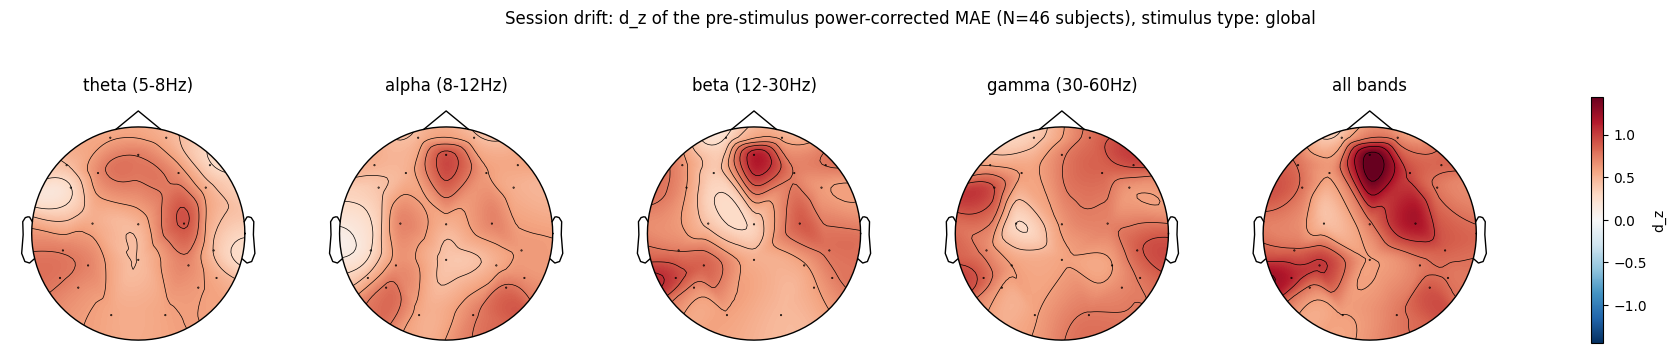

Session drift: d_z of the pre-stimulus power-corrected MAE, d_z:
  theta (5-8Hz)    max: C4 +0.92, A1 +0.77, FZ +0.74   min: F7 +0.29, T2 +0.32, T4 +0.44
  alpha (8-12Hz)   max: FZ +0.94, T6 +0.78, T5 +0.78   min: T3 +0.29, PZ +0.41, F7 +0.41
  beta (12-30Hz)   max: FZ +1.13, A1 +0.97, C4 +0.88   min: FP1 +0.31, CZ +0.34, F3 +0.37
  gamma (30-60Hz)  max: T2 +0.93, F7 +0.90, T4 +0.86   min: C3 +0.30, FP1 +0.39, PZ +0.58
  all bands        max: FZ +1.45, C4 +1.19, A1 +1.10   min: C3 +0.45, FP1 +0.49, PZ +0.59


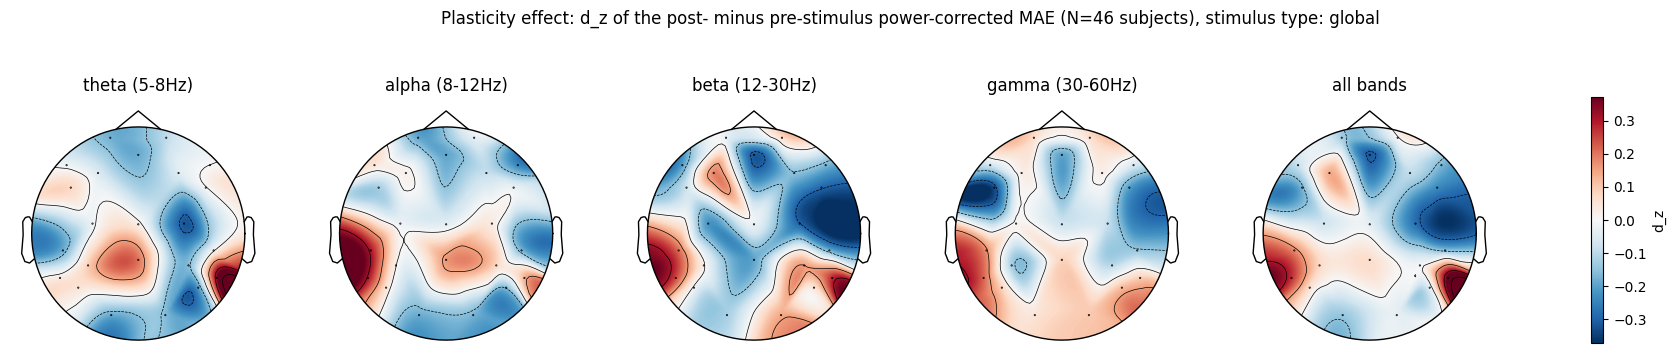

Plasticity effect: d_z of the post- minus pre-stimulus power-corrected MAE, d_z:
  theta (5-8Hz)    max: A2 +0.33, PZ +0.20, P3 +0.10   min: C4 -0.32, T6 -0.20, FZ -0.18
  alpha (8-12Hz)   max: A1 +0.29, T3 +0.28, PZ +0.16   min: T2 -0.24, FZ -0.19, FP1 -0.19
  beta (12-30Hz)   max: A2 +0.27, A1 +0.24, T3 +0.20   min: FZ -0.32, C4 -0.30, F8 -0.29
  gamma (30-60Hz)  max: A1 +0.21, T3 +0.16, T6 +0.11   min: F7 -0.32, F8 -0.20, FZ -0.20
  all bands        max: A2 +0.37, A1 +0.27, T3 +0.17   min: FZ -0.31, C4 -0.28, F8 -0.24


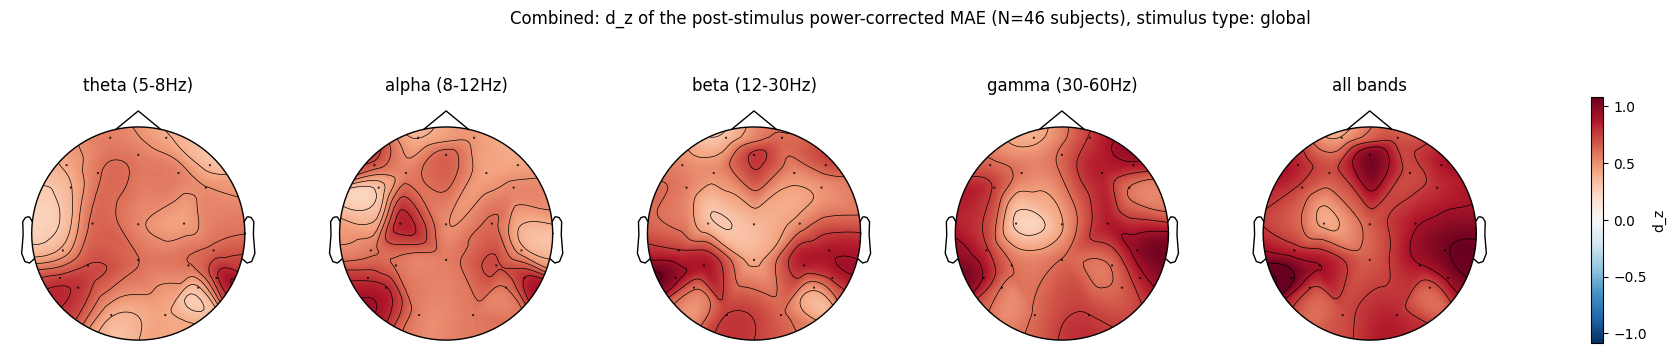

Combined: d_z of the post-stimulus power-corrected MAE, d_z:
  theta (5-8Hz)    max: T5 +0.78, A2 +0.78, A1 +0.74   min: T2 +0.35, T6 +0.38, F7 +0.39
  alpha (8-12Hz)   max: C3 +0.85, T5 +0.81, A2 +0.80   min: F7 +0.33, FP1 +0.40, T2 +0.44
  beta (12-30Hz)   max: A1 +0.95, P3 +0.89, T4 +0.87   min: C3 +0.33, FP1 +0.35, CZ +0.36
  gamma (30-60Hz)  max: T4 +0.96, A1 +0.89, T2 +0.86   min: C3 +0.27, FP1 +0.41, CZ +0.44
  all bands        max: A1 +1.09, T4 +1.04, FZ +1.01   min: C3 +0.42, FP1 +0.47, CZ +0.66


In [13]:
info = data_processor.create_topomap_info()  # 10-20 labels at the positions of the recording HydroCel electrodes
EFFECT_LABELS = {"d_z": "d_z", "mean": "mean change (dB)"}
CH_NAMES = [name.replace("EEG ", "").replace("-REF", "") for name in settings.CHORDER_STANDARD]


def plot_effect_topomaps(b_means, p_means, title, file_name, effect_size):
    """
    One topomap per band (+ all bands) of the change post-patching - baseline ("d_z" or "mean"), channels without a value are left out.
    Prints the 3 channels with the largest and the 3 with the smallest value of every band.
    """
    effect_by_band = data_processor.calc_subjectwise_channel_d(b_means, p_means, group_by_bands=True, effect_size=effect_size)
    # dict {"ch_0": value, ...} -> array in channel order, matching info
    vals_by_band = {band: np.array([effect[f"ch_{ch}"] for ch in range(settings.N_CHANNELS)]) for band, effect in effect_by_band.items()}
    # one symmetric colour scale shared by all bands, so the colours are comparable between the panels
    if effect_size == "d_z" and topomap_vlim is not None:
        max_val = topomap_vlim
    else:
        max_val = max(np.nanmax(np.abs(vals)) for vals in vals_by_band.values())

    fig, axes = plt.subplots(1, len(vals_by_band), figsize=(24, 4))
    for ax, (band, vals) in zip(axes, vals_by_band.items()):
        keep = np.flatnonzero(np.isfinite(vals))
        im, _ = mne.viz.plot_topomap(vals[keep], mne.pick_info(info, keep), axes=ax, show=False, vlim=(-max_val, max_val), cmap="RdBu_r")
        ax.set_title(band)
    fig.colorbar(im, ax=axes, shrink=0.8, label=EFFECT_LABELS[effect_size])
    n_subjects = len([s for s in b_means["ch_0"] if s in p_means["ch_0"]])
    plt.suptitle(f"{title} (N={n_subjects} subjects), stimulus type: {', '.join(conditions)}", y=1.02)
    plotting.save_button(fig, save_dir=plot_root / "bandwise_topomaps", default_name=f"{file_name}_{an_suffix}_{excl_suffix}")
    plt.show()

    # the 3 largest and 3 smallest channels of every band, channels without a value left out
    print(f"{title}, {EFFECT_LABELS[effect_size]}:")
    for band, vals in vals_by_band.items():
        order = [ch for ch in np.argsort(vals) if np.isfinite(vals[ch])]
        largest = ", ".join(f"{CH_NAMES[ch]} {vals[ch]:+.2f}" for ch in order[::-1][:3])
        smallest = ", ".join(f"{CH_NAMES[ch]} {vals[ch]:+.2f}" for ch in order[:3])
        print(f"  {band:16s} max: {largest:30s} min: {smallest}")


def plot_session_contrasts(metric, label, effect_size):
    """The three topomaps of one metric and effect size: session drift, plasticity effect and combined."""
    b, p = subject_means[metric]["baseline"], subject_means[metric]["postpatch"]
    what = EFFECT_LABELS[effect_size]
    plot_effect_topomaps(b["pre"], p["pre"],
                         f"Session drift: {what} of the pre-stimulus {label}", f"{metric}_{effect_size}_drift", effect_size)
    plot_effect_topomaps(data_processor.subtract_channel_dicts(b["post"], b["pre"]), data_processor.subtract_channel_dicts(p["post"], p["pre"]),
                         f"Plasticity effect: {what} of the post- minus pre-stimulus {label}", f"{metric}_{effect_size}_plasticity", effect_size)
    plot_effect_topomaps(b["post"], p["post"],
                         f"Combined: {what} of the post-stimulus {label}", f"{metric}_{effect_size}_combined", effect_size)


plot_session_contrasts("corrected_mae", "power-corrected MAE", "d_z")

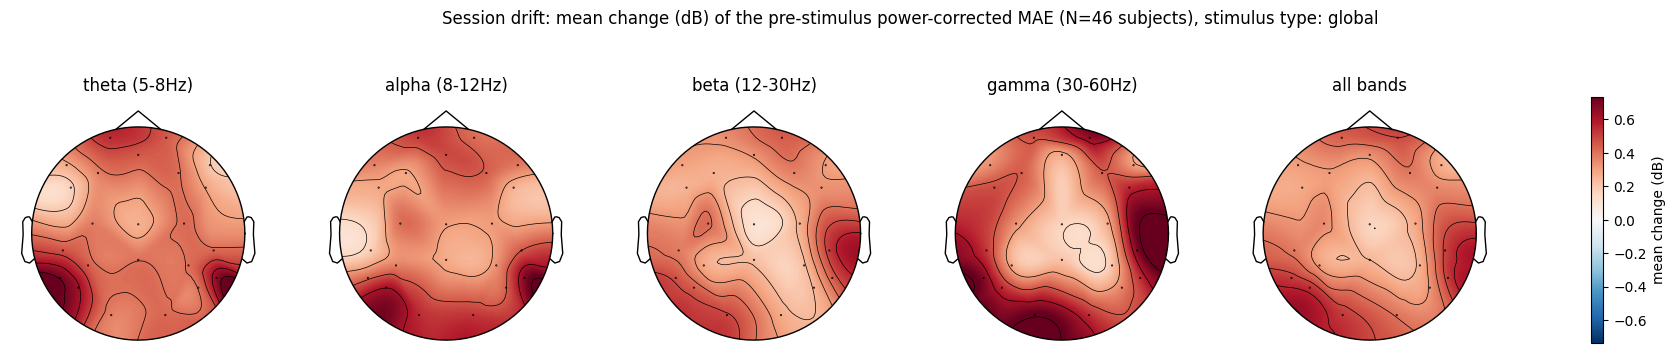

Session drift: mean change (dB) of the pre-stimulus power-corrected MAE, mean change (dB):
  theta (5-8Hz)    max: A1 +0.69, A2 +0.65, T5 +0.61   min: F7 +0.18, T2 +0.21, CZ +0.26
  alpha (8-12Hz)   max: A2 +0.67, T5 +0.60, O1 +0.54   min: T3 +0.19, F8 +0.26, PZ +0.28
  beta (12-30Hz)   max: T4 +0.51, O1 +0.49, A1 +0.46   min: CZ +0.11, PZ +0.22, P4 +0.23
  gamma (30-60Hz)  max: O1 +0.74, T4 +0.67, A1 +0.66   min: CZ +0.16, P4 +0.20, PZ +0.21
  all bands        max: T5 +0.53, O1 +0.52, A2 +0.51   min: CZ +0.16, PZ +0.24, P4 +0.26


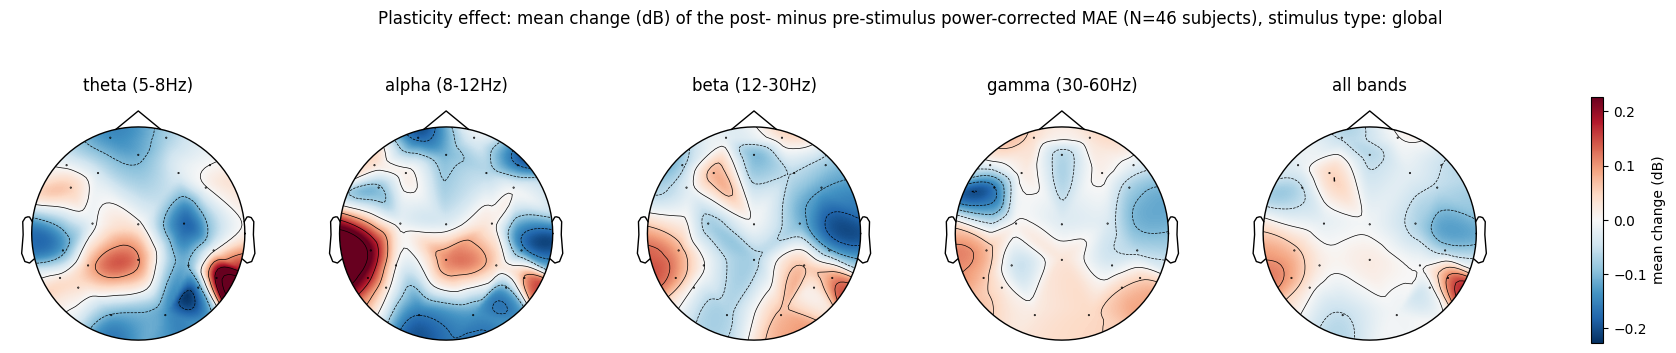

Plasticity effect: mean change (dB) of the post- minus pre-stimulus power-corrected MAE, mean change (dB):
  theta (5-8Hz)    max: A2 +0.23, PZ +0.10, P3 +0.07   min: C4 -0.18, FP1 -0.14, O2 -0.13
  alpha (8-12Hz)   max: T3 +0.22, A1 +0.18, PZ +0.11   min: FP1 -0.17, T2 -0.16, O1 -0.16
  beta (12-30Hz)   max: A1 +0.09, A2 +0.09, T3 +0.08   min: F8 -0.12, T4 -0.11, C4 -0.10
  gamma (30-60Hz)  max: T3 +0.07, A1 +0.06, T6 +0.05   min: F7 -0.15, F8 -0.07, FZ -0.06
  all bands        max: A2 +0.11, A1 +0.08, T3 +0.06   min: T4 -0.07, C4 -0.07, FZ -0.06


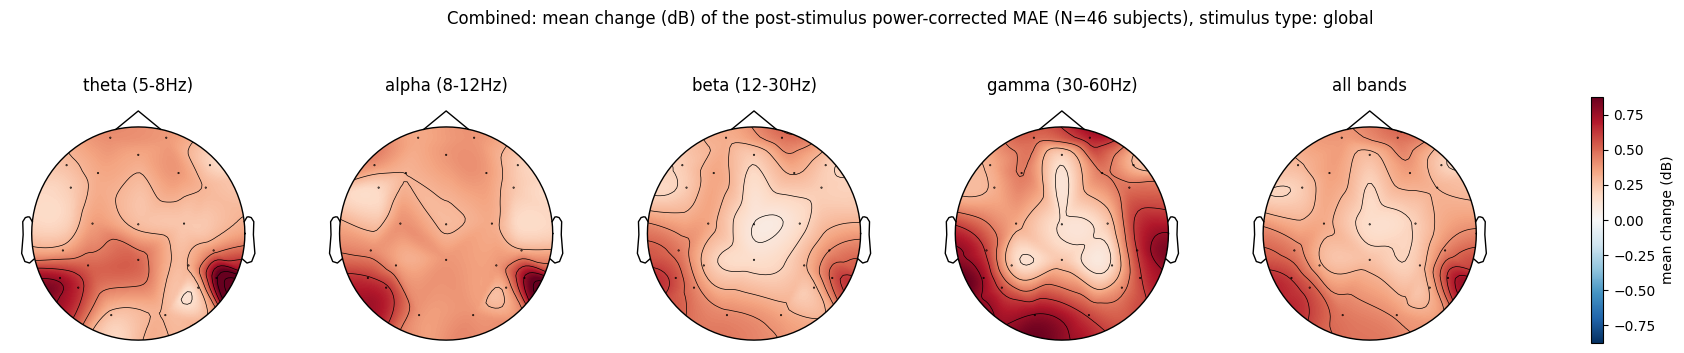

Combined: mean change (dB) of the post-stimulus power-corrected MAE, mean change (dB):
  theta (5-8Hz)    max: A2 +0.88, A1 +0.71, T5 +0.65   min: T2 +0.21, F7 +0.23, C4 +0.24
  alpha (8-12Hz)   max: A2 +0.76, T5 +0.62, A1 +0.61   min: F7 +0.19, T2 +0.22, F8 +0.24
  beta (12-30Hz)   max: A1 +0.56, A2 +0.53, FP2 +0.47  min: CZ +0.10, PZ +0.15, C4 +0.16
  gamma (30-60Hz)  max: O1 +0.76, A1 +0.73, FP2 +0.67  min: CZ +0.14, P4 +0.17, FZ +0.21
  all bands        max: A2 +0.62, A1 +0.59, T5 +0.54   min: CZ +0.16, C4 +0.21, T2 +0.22


In [14]:
plot_session_contrasts("corrected_mae", "power-corrected MAE", "mean")

### The same maps for the uncorrected MAE
For comparison: differences from the corrected maps above come from changes in power (the error shrinks where power rises and grows where it falls).

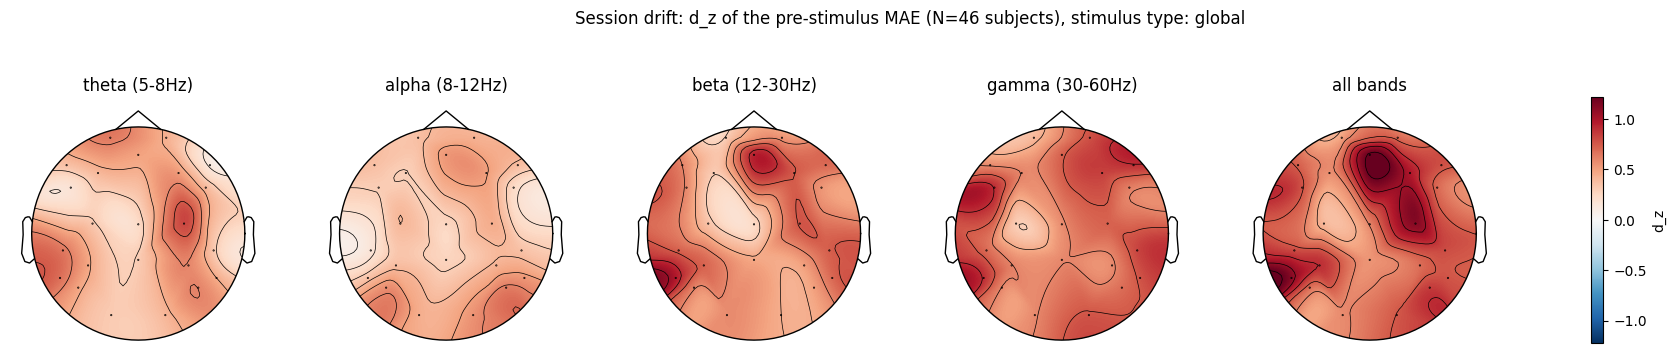

Session drift: d_z of the pre-stimulus MAE, d_z:
  theta (5-8Hz)    max: C4 +0.82, A1 +0.67, T3 +0.64   min: T2 +0.13, F7 +0.18, CZ +0.25
  alpha (8-12Hz)   max: T6 +0.62, T5 +0.56, O2 +0.55   min: T3 +0.17, F8 +0.24, CZ +0.26
  beta (12-30Hz)   max: A1 +0.97, FZ +0.95, C4 +0.76   min: CZ +0.25, F3 +0.31, FP1 +0.31
  gamma (30-60Hz)  max: F7 +0.89, T2 +0.89, A1 +0.88   min: C3 +0.31, FP1 +0.41, CZ +0.57
  all bands        max: FZ +1.22, C4 +1.12, A1 +1.10   min: C3 +0.40, FP1 +0.52, PZ +0.54


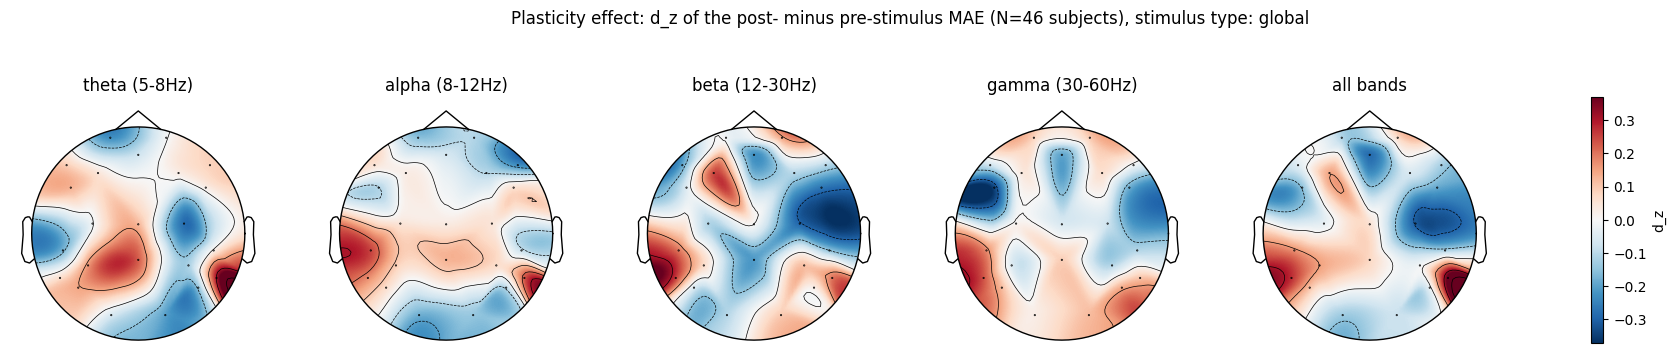

Plasticity effect: d_z of the post- minus pre-stimulus MAE, d_z:
  theta (5-8Hz)    max: A2 +0.31, PZ +0.22, P3 +0.17   min: C4 -0.29, FP1 -0.22, O2 -0.20
  alpha (8-12Hz)   max: T3 +0.24, A2 +0.23, A1 +0.17   min: T2 -0.23, O1 -0.18, FP1 -0.15
  beta (12-30Hz)   max: A1 +0.25, F3 +0.25, A2 +0.19   min: C4 -0.29, F8 -0.27, FZ -0.23
  gamma (30-60Hz)  max: A1 +0.23, T3 +0.17, T6 +0.13   min: F7 -0.33, FZ -0.20, F8 -0.18
  all bands        max: A2 +0.37, A1 +0.27, T3 +0.16   min: C4 -0.31, FZ -0.28, F8 -0.19


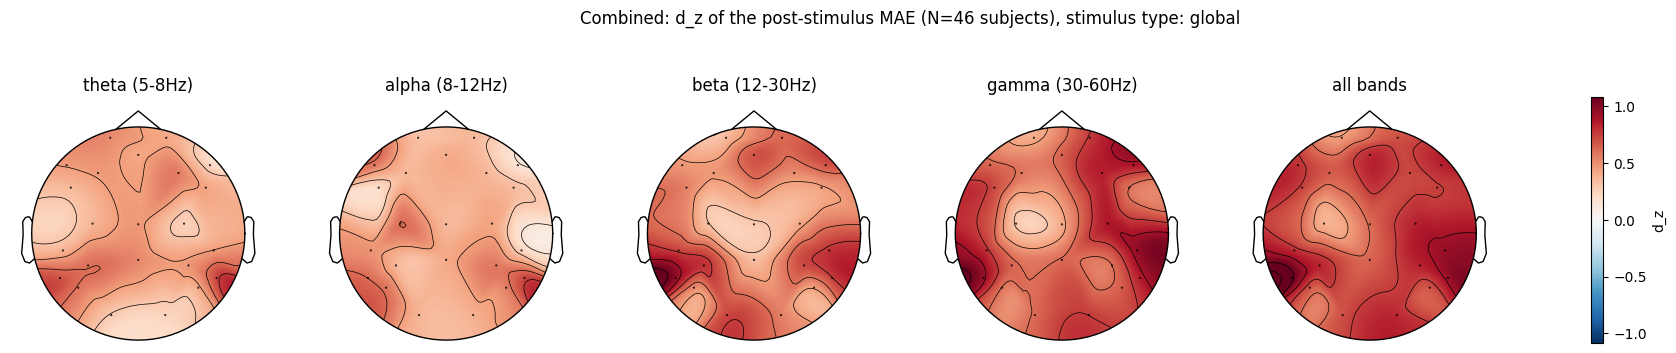

Combined: d_z of the post-stimulus MAE, d_z:
  theta (5-8Hz)    max: A2 +0.72, A1 +0.68, P3 +0.59   min: T2 +0.23, O2 +0.24, C4 +0.26
  alpha (8-12Hz)   max: A2 +0.71, C3 +0.60, A1 +0.60   min: T2 +0.17, F7 +0.22, T4 +0.24
  beta (12-30Hz)   max: A1 +0.96, P3 +0.79, T4 +0.78   min: CZ +0.28, C3 +0.31, PZ +0.33
  gamma (30-60Hz)  max: T4 +0.95, A1 +0.93, C4 +0.87   min: C3 +0.28, CZ +0.41, FP1 +0.41
  all bands        max: A1 +1.08, T4 +0.94, A2 +0.93   min: C3 +0.38, FP1 +0.47, CZ +0.61


In [15]:
plot_session_contrasts("mae", "MAE", "d_z")

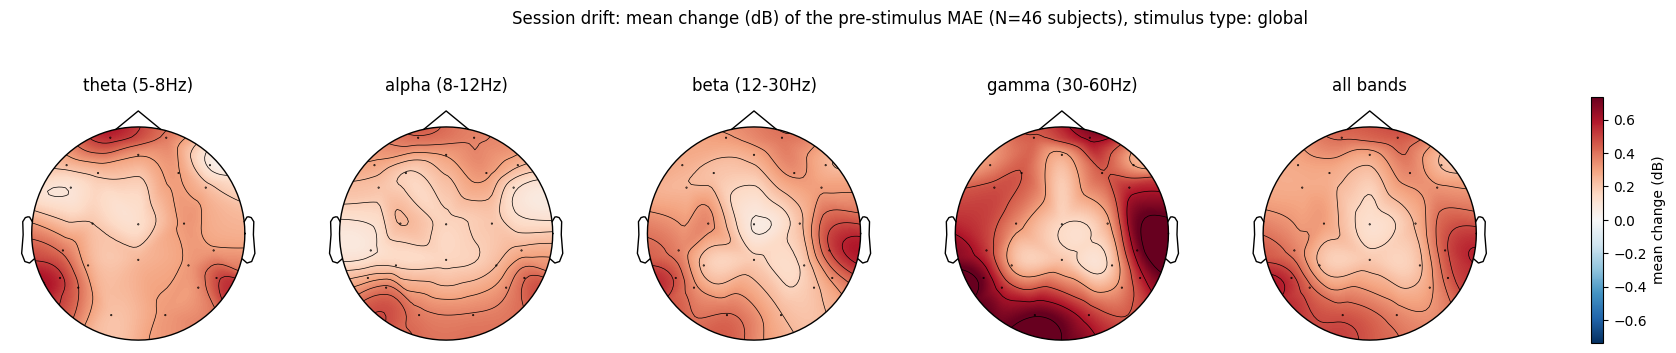

Session drift: mean change (dB) of the pre-stimulus MAE, mean change (dB):
  theta (5-8Hz)    max: FP1 +0.54, A1 +0.52, A2 +0.48  min: T2 +0.08, F7 +0.11, CZ +0.13
  alpha (8-12Hz)   max: A2 +0.41, FP1 +0.41, O1 +0.38  min: T3 +0.10, F8 +0.14, PZ +0.16
  beta (12-30Hz)   max: T4 +0.48, A1 +0.46, O1 +0.41   min: CZ +0.07, PZ +0.18, P4 +0.19
  gamma (30-60Hz)  max: O1 +0.74, A1 +0.69, T4 +0.66   min: CZ +0.15, P4 +0.20, PZ +0.20
  all bands        max: A1 +0.51, T4 +0.46, O1 +0.46   min: CZ +0.12, PZ +0.20, P4 +0.22


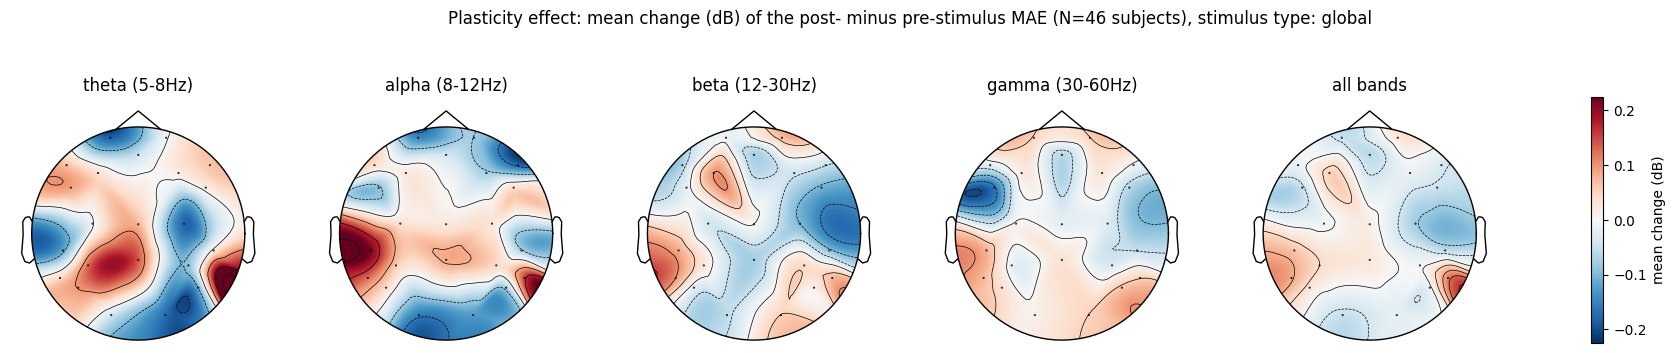

Plasticity effect: mean change (dB) of the post- minus pre-stimulus MAE, mean change (dB):
  theta (5-8Hz)    max: A2 +0.22, PZ +0.14, P3 +0.13   min: FP1 -0.18, C4 -0.18, O2 -0.17
  alpha (8-12Hz)   max: T3 +0.20, A2 +0.15, A1 +0.12   min: T2 -0.17, O1 -0.15, FP1 -0.14
  beta (12-30Hz)   max: F3 +0.10, A1 +0.10, T3 +0.08   min: F8 -0.11, C4 -0.10, T4 -0.09
  gamma (30-60Hz)  max: T3 +0.07, A1 +0.07, T6 +0.06   min: F7 -0.16, FZ -0.06, F8 -0.06
  all bands        max: A2 +0.11, A1 +0.08, T3 +0.06   min: C4 -0.08, FZ -0.06, T4 -0.06


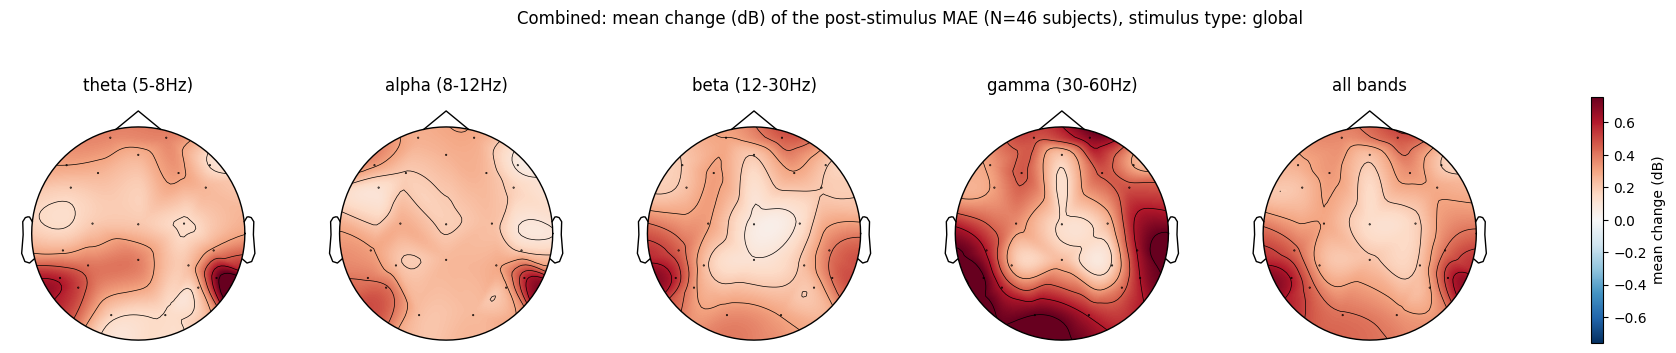

Combined: mean change (dB) of the post-stimulus MAE, mean change (dB):
  theta (5-8Hz)    max: A2 +0.70, A1 +0.57, T5 +0.50   min: C4 +0.14, T2 +0.14, O2 +0.15
  alpha (8-12Hz)   max: A2 +0.56, T5 +0.41, A1 +0.39   min: T2 +0.08, F7 +0.12, F8 +0.17
  beta (12-30Hz)   max: A1 +0.56, FP2 +0.46, T3 +0.44  min: CZ +0.07, PZ +0.11, C4 +0.12
  gamma (30-60Hz)  max: A1 +0.76, O1 +0.75, FP2 +0.68  min: CZ +0.13, P4 +0.16, FZ +0.21
  all bands        max: A1 +0.59, A2 +0.55, FP2 +0.47  min: CZ +0.13, C4 +0.17, T2 +0.20


In [16]:
plot_session_contrasts("mae", "MAE", "mean")

## plotting bandwise amplitude changes pre- and post-patching

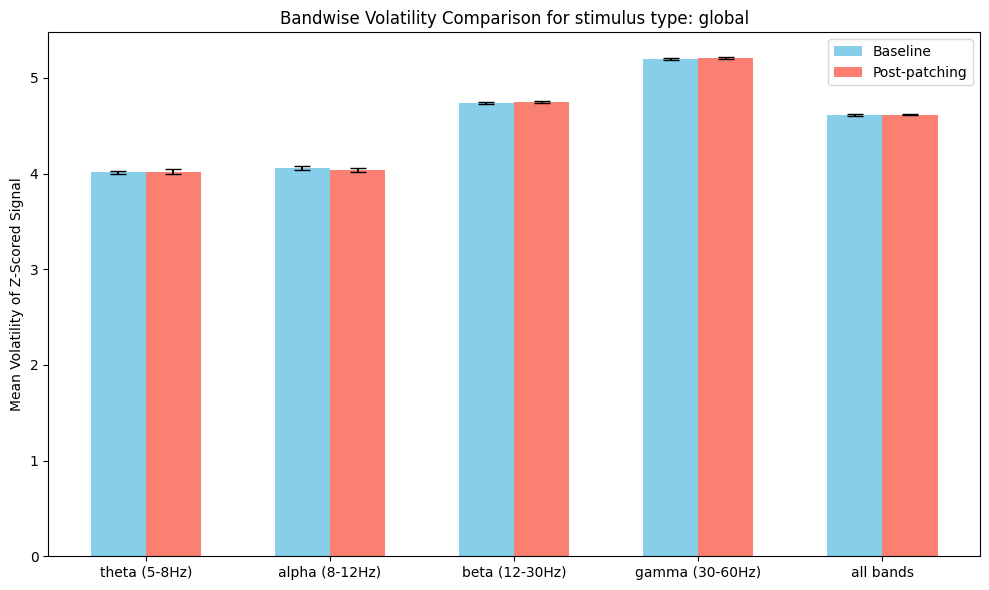

In [17]:
ampl_bw_b, sem_bw_b= data_processor.get_subjectwise_metric_mean(baseline_merged, bands=bands, metric_name="signal_volatility_bandwise")
ampl_bw_p, sem_bw_p = data_processor.get_subjectwise_metric_mean(postpatch_merged, bands=bands, metric_name="signal_volatility_bandwise")



x_text = list(ampl_bw_b.keys())



fig, ax = plt.subplots(figsize=(10, 6))
width = 0.3
x = np.arange(len(x_text))
title = f'Bandwise Volatility Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, ampl_bw_b.values(), width=width, yerr=sem_bw_b.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, ampl_bw_p.values(), width=width, yerr=sem_bw_p.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(x_text)

# Formatting
ax.set_ylabel('Mean Volatility of Z-Scored Signal')
ax.set_title(title)
ax.legend()

plotting.save_button(fig, save_dir=plot_root / "bandwise_volatility", default_name=f"bw_vols_{an_suffix}_{excl_suffix}")

plt.tight_layout()
plt.show()

### Paired tests of the volatility change
Per band: change of the subject-mean volatility (post - baseline) in % of the baseline mean, Cohen's d_z, paired t-test, Wilcoxon signed-rank test and the number of subjects whose volatility increased.
A non-significant change doesn't make the volatility adjustment unnecessary: the adjustment is needed because each subject's MAE change depends on their own volatility change.

In [18]:
b_vol_means, _ = data_processor.calc_subjectwise_metric_stats(baseline_merged, bands, "signal_volatility")
p_vol_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, "signal_volatility")
subjects = [s for s in b_vol_means if s in p_vol_means]

print(f"Volatility change after patching ({time_window} window, N={len(subjects)} subjects)")
print(f"{'band':16s} {'change':>8s} {'d_z':>6s} {'t-test p':>9s} {'Wilcoxon p':>11s} {'increased':>10s}")
for band in [*bands, "all bands"]:
    pre = np.array([b_vol_means[s][band] for s in subjects])
    post = np.array([p_vol_means[s][band] for s in subjects])
    diffs = post - pre
    print(f"{band:16s} {100 * diffs.mean() / pre.mean():+7.2f}% {diffs.mean() / diffs.std(ddof=1):+6.2f} "
          f"{ttest_rel(post, pre).pvalue:9.3f} {wilcoxon(diffs).pvalue:11.3f} {np.sum(diffs > 0):5d}/{len(diffs)}")


Volatility change after patching (analysis window, N=46 subjects)
band               change    d_z  t-test p  Wilcoxon p  increased
theta (5-8Hz)      +0.15%  +0.05     0.760       0.914    22/46
alpha (8-12Hz)     -0.49%  -0.18     0.223       0.263    21/46
beta (12-30Hz)     +0.21%  +0.12     0.407       0.495    25/46
gamma (30-60Hz)    +0.25%  +0.19     0.198       0.111    27/46
all bands          +0.11%  +0.11     0.470       0.323    28/46


## Subject-wise gamma NMAE comparison pre- and post-patching

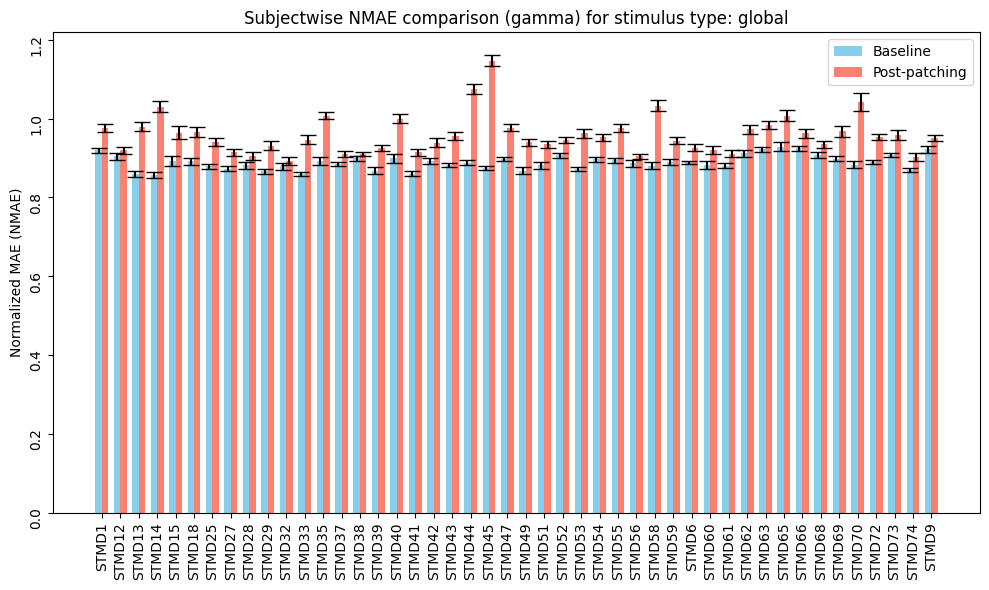

In [19]:
subjectwise_nmae_b, subjectwise_nmae_sem_b = data_processor.calc_subjectwise_metric_stats(baseline_merged, ["gamma (30-45Hz)"], metric="nmae")
subjectwise_nmae_p, subjectwise_nmae_sem_p = data_processor.calc_subjectwise_metric_stats(postpatch_merged, ["gamma (30-45Hz)"], metric="nmae")

band = "all bands"

sb_baseline_nmae = {s: subjectwise_nmae_b[s][band] for s in sorted(subjectwise_nmae_b)}
sb_baseline_sem  = {s: subjectwise_nmae_sem_b[s][band] for s in sorted(subjectwise_nmae_b)}
sb_postpatch_nmae = {s: subjectwise_nmae_p[s][band] for s in sorted(subjectwise_nmae_b)}
sb_postpatch_sem  = {s: subjectwise_nmae_sem_p[s][band] for s in sorted(subjectwise_nmae_b)}

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(subjectwise_nmae_b.keys()))
title = f'Subjectwise NMAE comparison (gamma) for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, sb_baseline_nmae.values(), width=width, yerr=sb_baseline_sem.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, sb_postpatch_nmae.values(), width=width, yerr=sb_postpatch_sem.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.tick_params(labelrotation=90)
ax.set_xticklabels(sb_baseline_nmae.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(title)
ax.legend()
plotting.save_button(fig, save_dir=plot_root / "subjectwise_e_comparison", default_name=f"nmae_subjectwise_gamma_{an_suffix}_{excl_suffix}")
plt.tight_layout()
plt.show()


## Plotting NMAE distribution of pre and post-patching trials

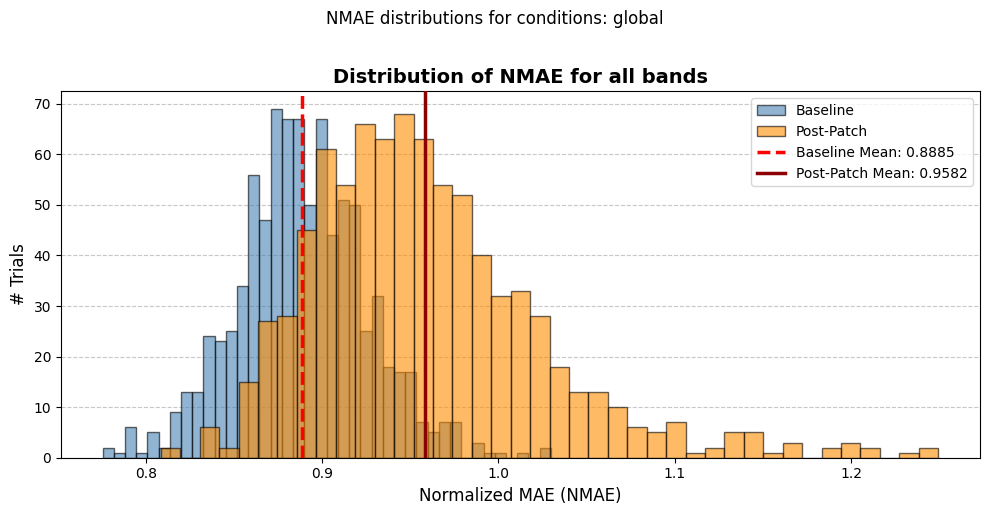

In [20]:
pre_nmaes = data_processor.extract_metric(baseline_merged, "nmae")
post_nmaes = data_processor.extract_metric(postpatch_merged, "nmae")

save_dir = plot_root / "nmae_dist_comparison"
plotting.distribution_viewer({"all bands": pre_nmaes}, {"all bands": post_nmaes}, title=f'NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"nmae_dist_all_bands_{an_suffix}_{excl_suffix}")



## Plotting bandwise NMAE distribution of pre and post-patching trials

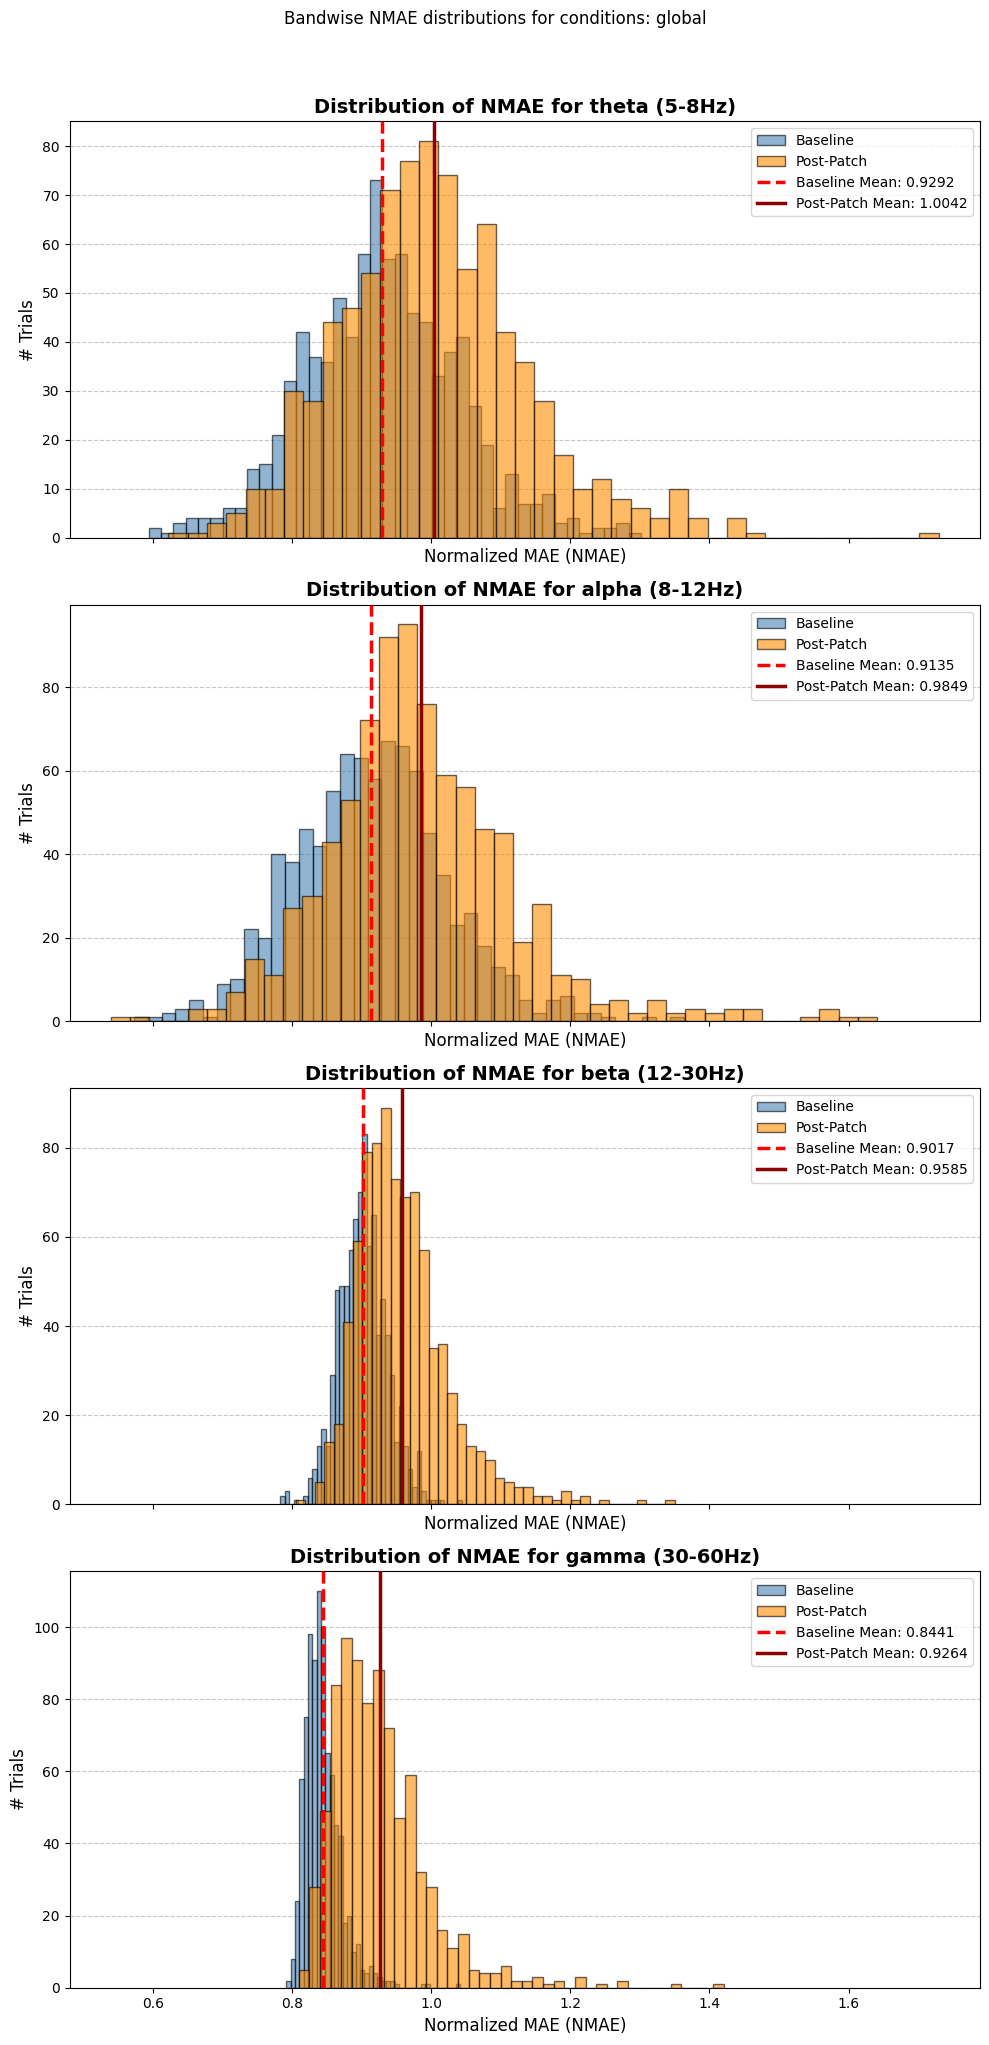

In [21]:
pre_nmaes_bw = data_processor.extract_metric(baseline_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)
post_nmaes_bw = data_processor.extract_metric(postpatch_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)

save_dir = plot_root / "nmae_dist_comparison"
plotting.distribution_viewer(pre_nmaes_bw, post_nmaes_bw, title=f'Bandwise NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"nmae_dist_bandwise_{an_suffix}_{excl_suffix}")



## Correlation of signal volatility and model error (NMAE vs MAE)
Trials of both sessions are pooled. Trials with higher volatility have higher MAE, a flat NMAE slope shows the normalization removes that dependence.

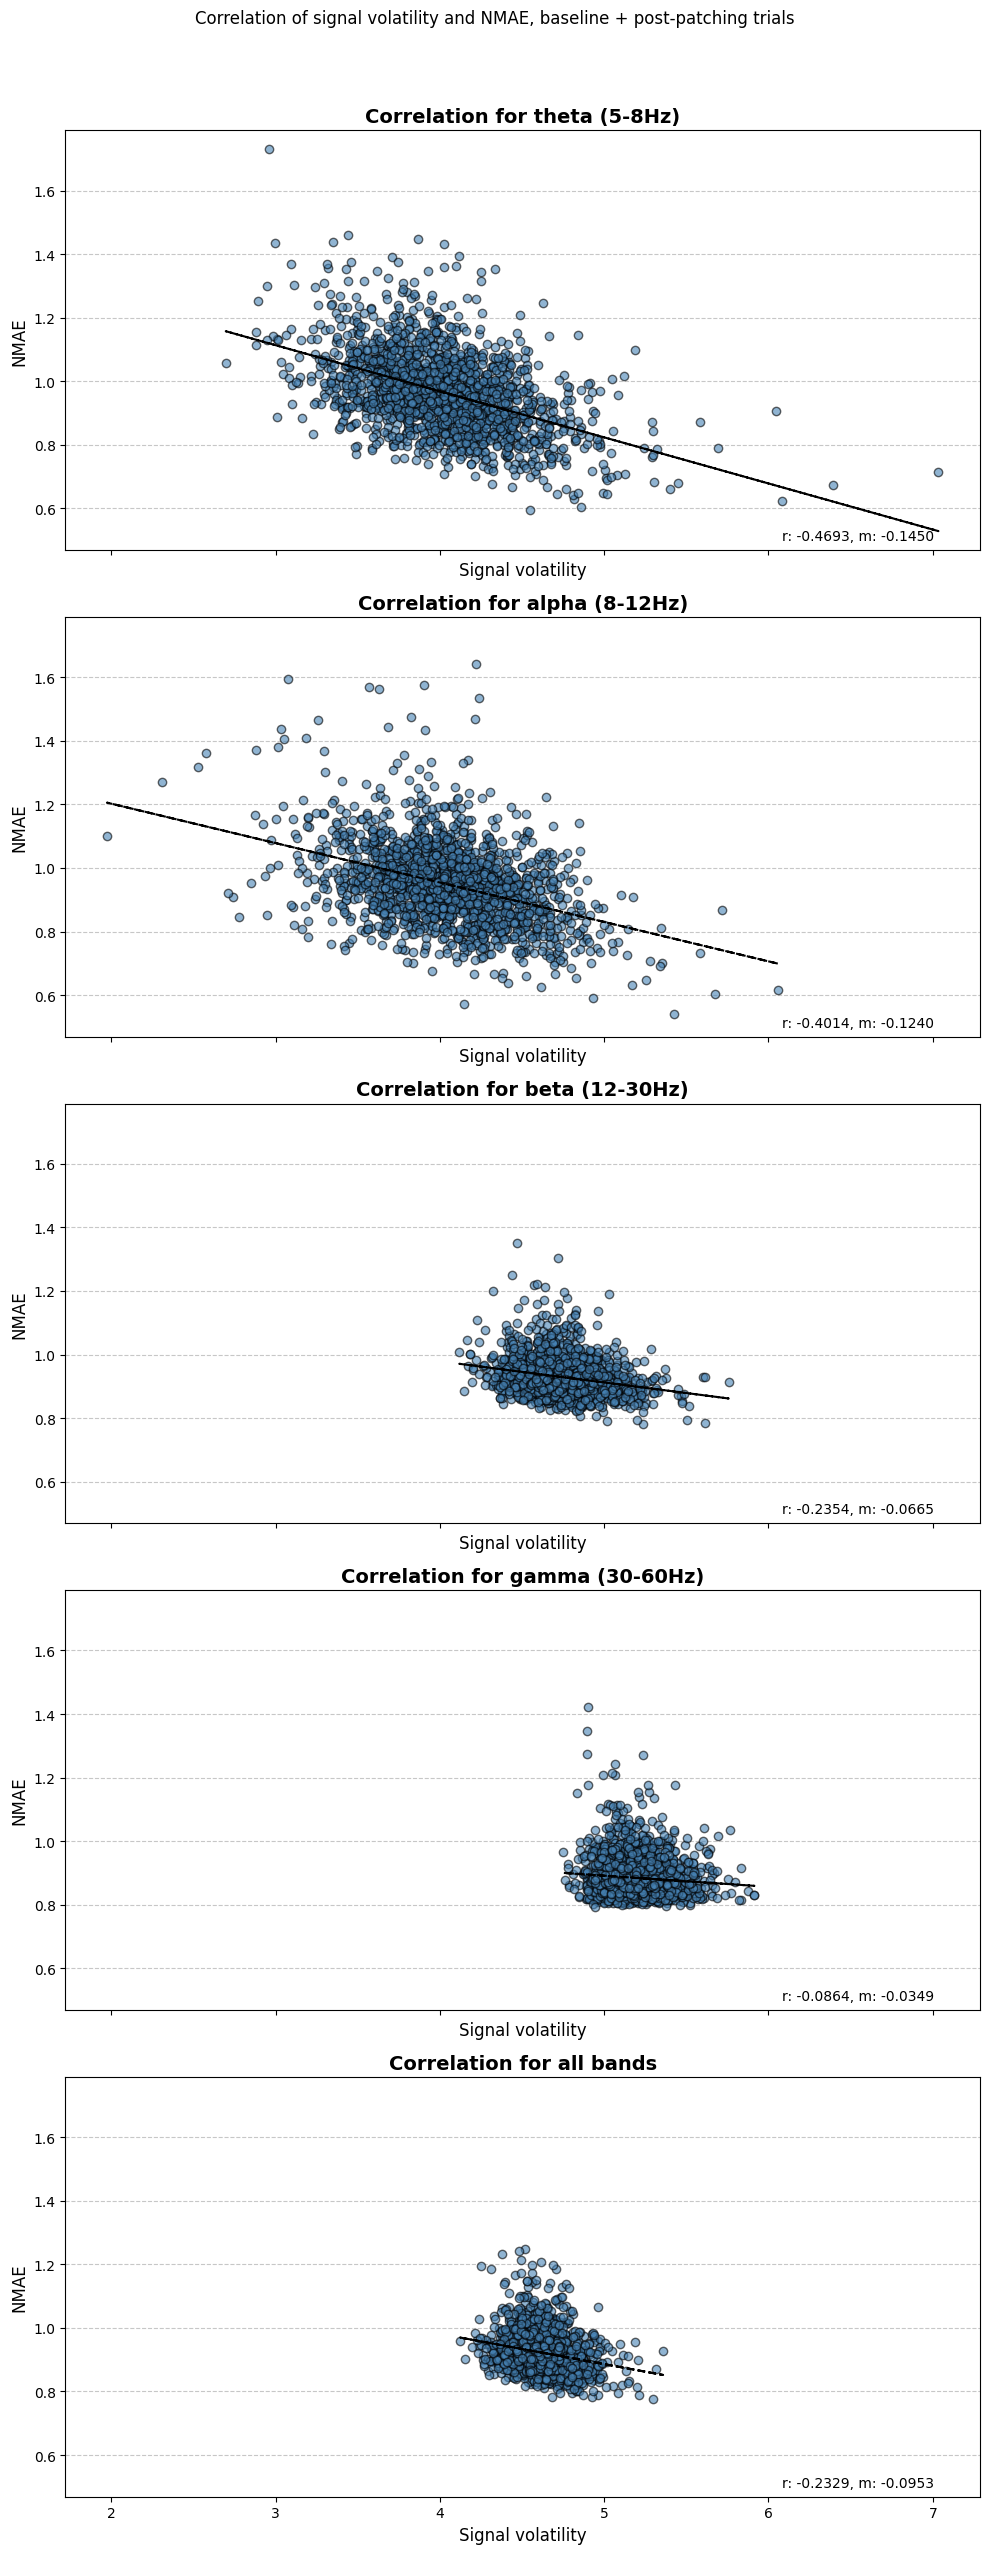

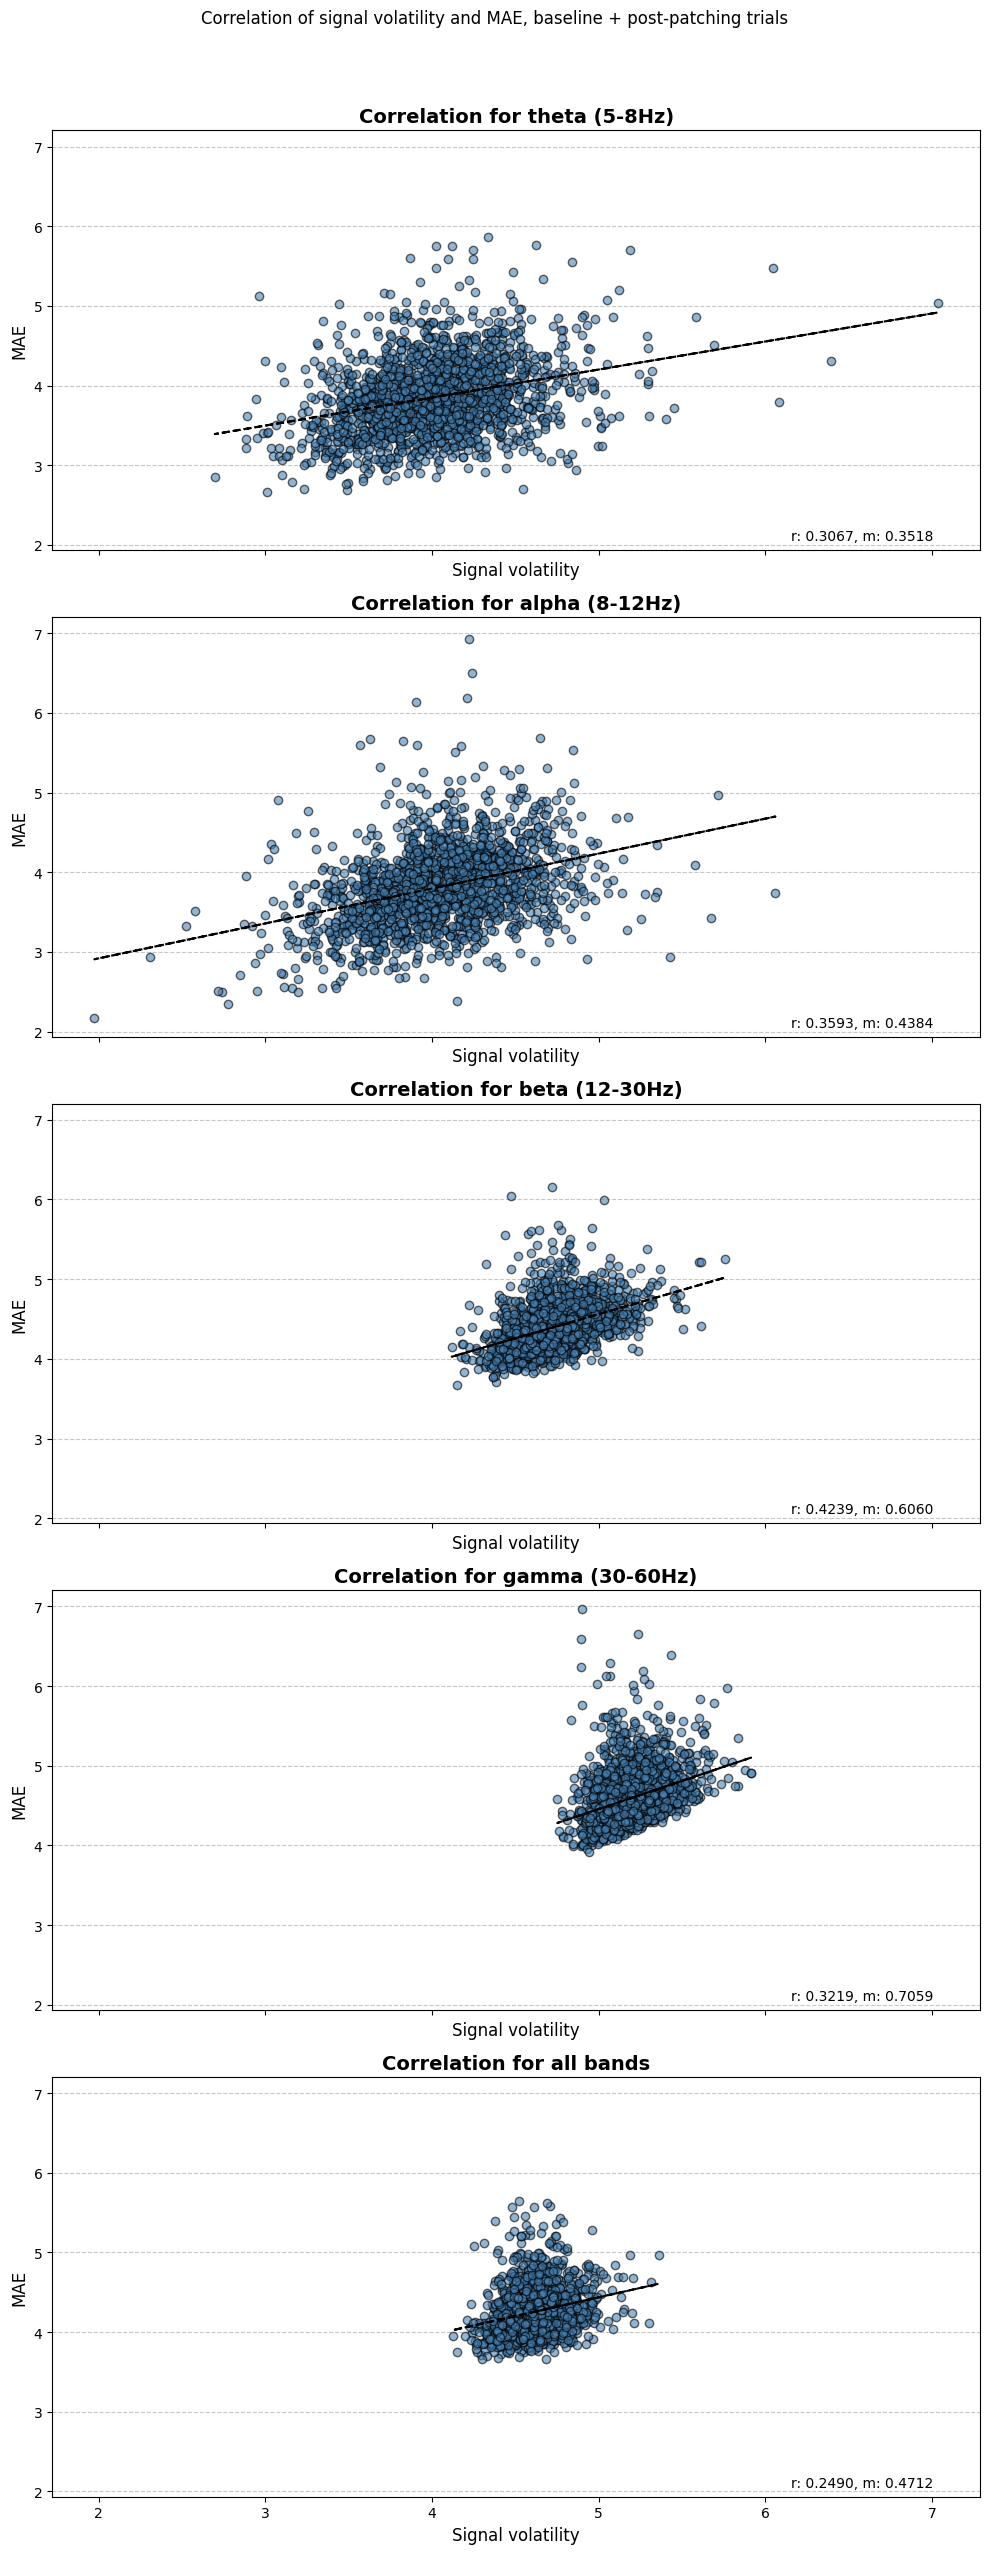

In [22]:
all_trials = baseline_merged + postpatch_merged
vols = data_processor.extract_metric(all_trials, "signal_volatility_bandwise", bands, bandwise=True)
vols["all bands"] = data_processor.extract_metric(all_trials, "signal_volatility")

for metric, label in [("nmae", "NMAE"), ("mae", "MAE")]:
    errors = data_processor.extract_metric(all_trials, f"{metric}_bandwise", bands, bandwise=True)
    errors["all bands"] = data_processor.extract_metric(all_trials, metric)
    plotting.correlation_plot(x=vols, y=errors, title=f'Correlation of signal volatility and {label}, baseline + post-patching trials',
                              xlabel='Signal volatility', ylabel=label,
                              save_dir=plot_root / "correlation_plots", save_name=f"{metric}_correlation_{an_suffix}_{excl_suffix}")


## Effect of the volatility correction (MAE, NMAE, corrected MAE)

### Volatility vs. error before and after the correction
Pooled trials of both sessions, with a separate fitted line per session. MAE grows with volatility, with the same slope in both sessions. NMAE divides by volatility, the corrected MAE subtracts the fitted within-subject dependence. Each panel has its own y scale, as the metrics have different units.

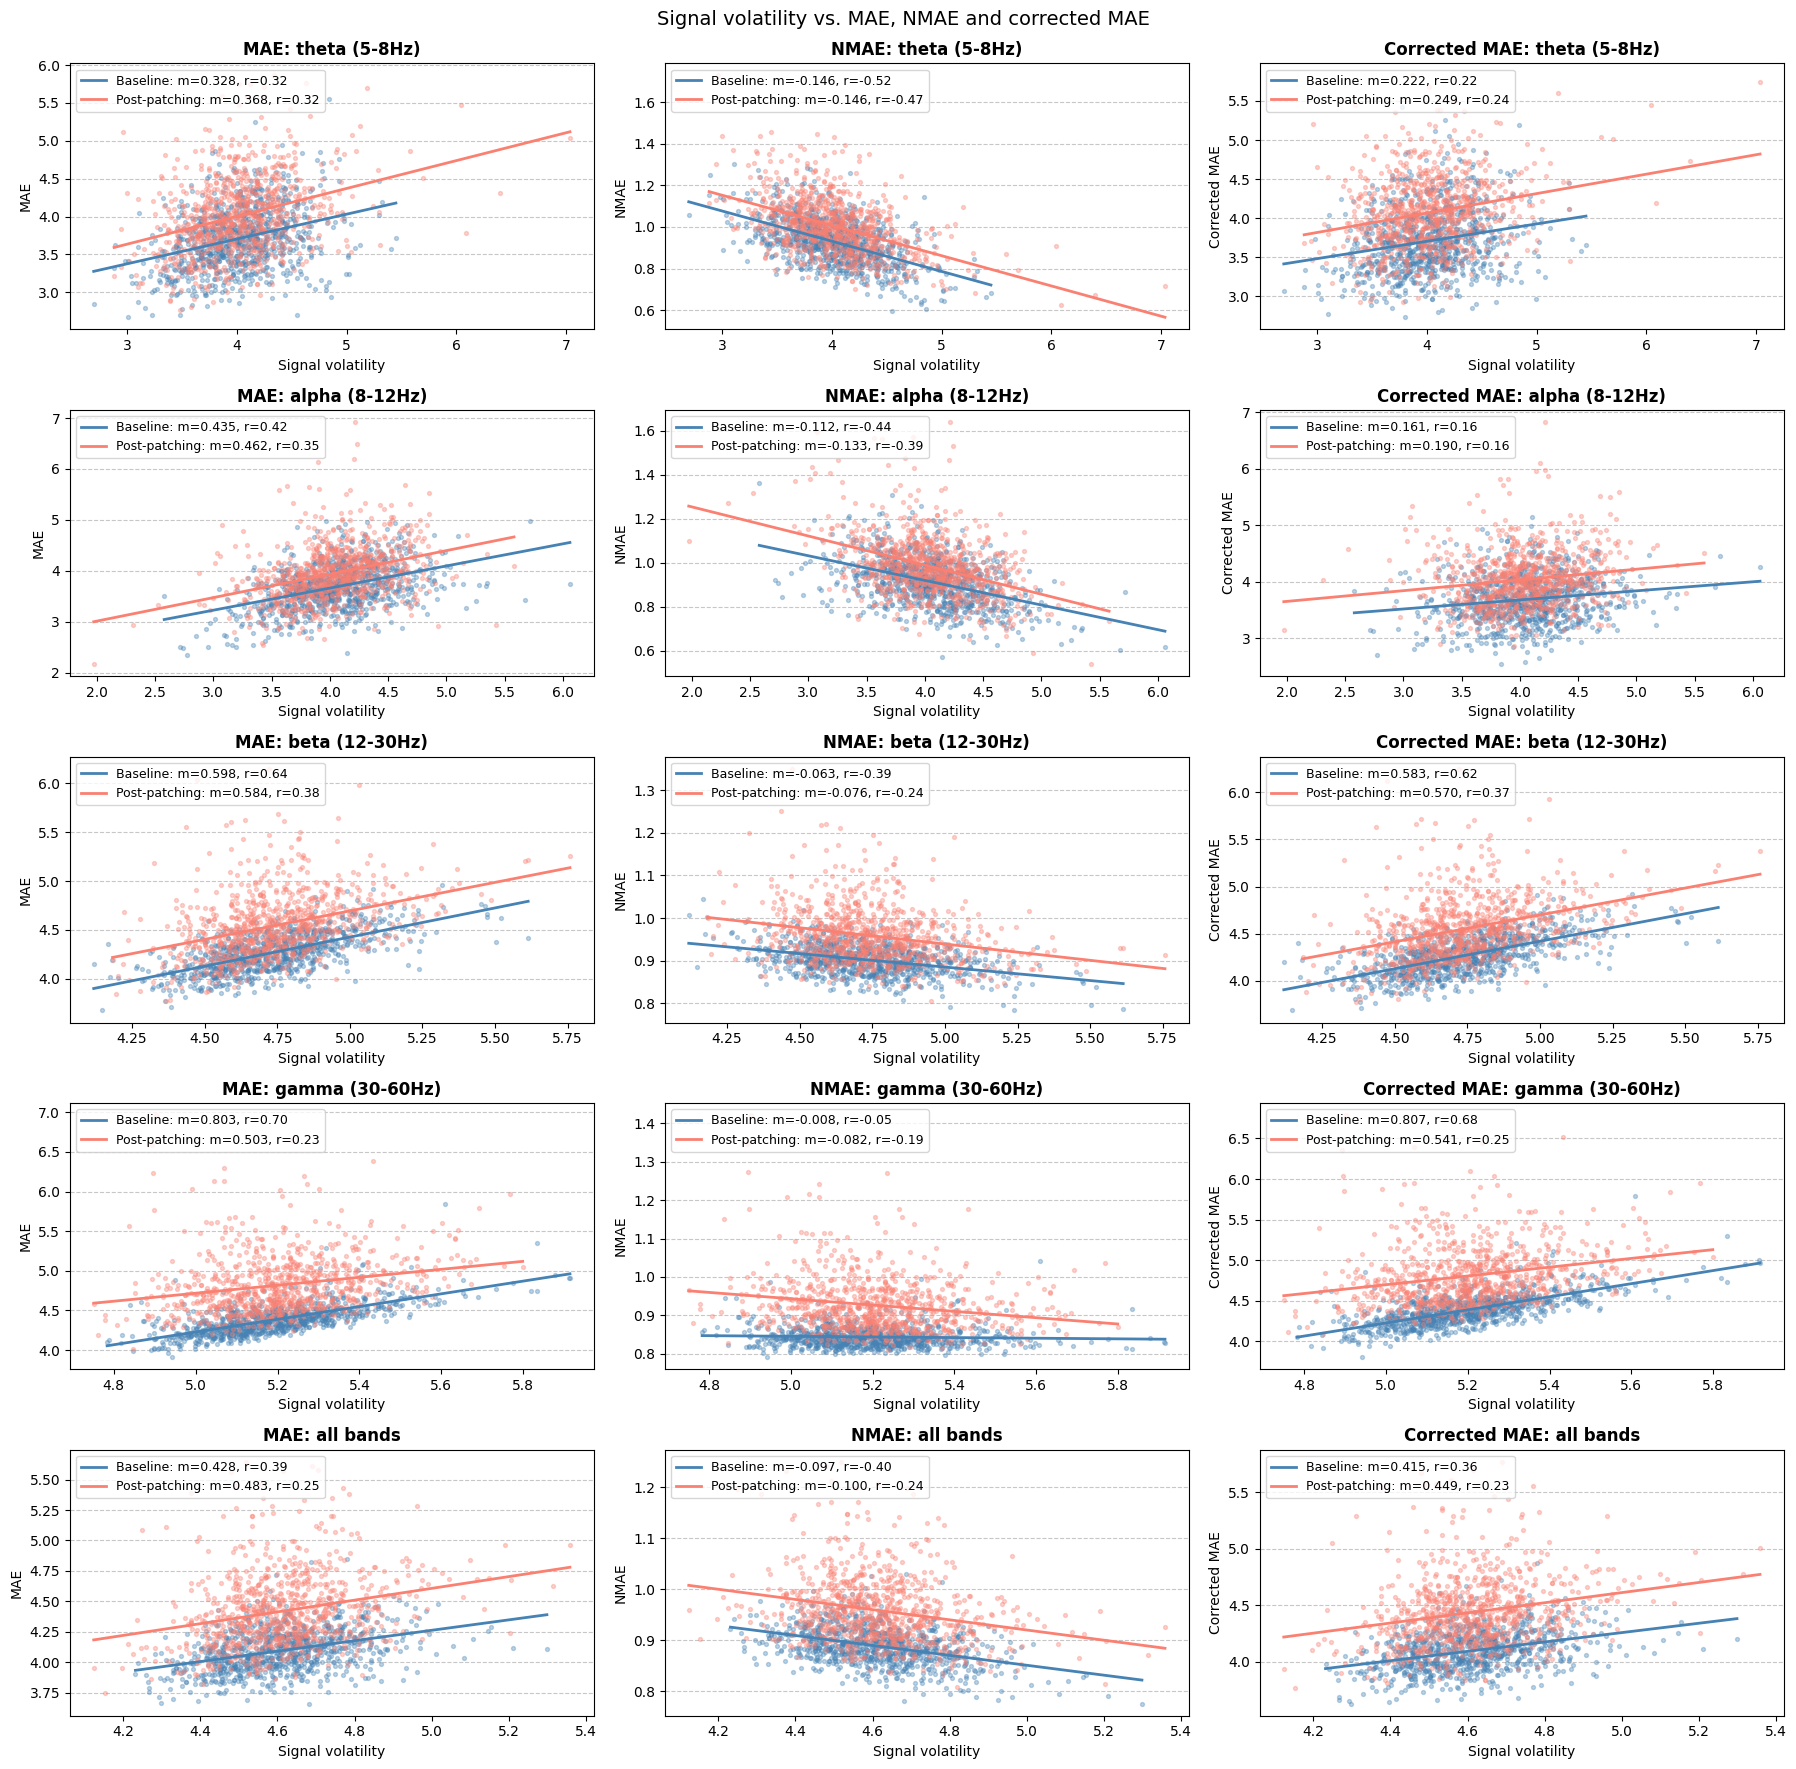

In [23]:
metrics_to_compare = {"MAE": "mae", "NMAE": "nmae", "Corrected MAE": "corrected_mae"}
band_keys = [*bands, "all bands"]

vols, errors = {}, {label: {} for label in metrics_to_compare}
for session, trials in [("Baseline", baseline_merged), ("Post-patching", postpatch_merged)]:
    vols[session] = data_processor.extract_metric(trials, "signal_volatility_bandwise", bands, bandwise=True)
    vols[session]["all bands"] = data_processor.extract_metric(trials, "signal_volatility")
    for label, metric in metrics_to_compare.items():
        errors[label][session] = data_processor.extract_metric(trials, f"{metric}_bandwise", bands, bandwise=True)
        errors[label][session]["all bands"] = data_processor.extract_metric(trials, metric)

plotting.session_correlation_plot(x_by_session=vols, y_by_metric=errors, xlabel="Signal volatility", sharey=False,
                                  title="Signal volatility vs. MAE, NMAE and corrected MAE",
                                  save_dir=plot_root / "correlation_plots", save_name=f"mae_correction_correlation_{an_suffix}_{excl_suffix}")


### Change of MAE, NMAE and corrected MAE after patching
Subject means per session. Bars show the mean of the subject differences (post-patching - baseline) ± SEM, in % of the mean baseline value of each metric, so the three metrics are comparable. The p-values are paired t-tests on the subject means.

band             |             MAE %      p |            NMAE %      p |   Corrected MAE %      p
theta (5-8Hz)    |             +8.30  0.000 |             +8.21  0.000 |             +9.82  0.000
alpha (8-12Hz)   |             +7.40  0.000 |             +7.94  0.000 |             +9.55  0.000
beta (12-30Hz)   |             +6.56  0.000 |             +6.34  0.000 |             +6.79  0.000
gamma (30-60Hz)  |             +9.88  0.000 |             +9.65  0.000 |             +9.62  0.000
all bands        |             +7.99  0.000 |             +7.87  0.000 |             +8.41  0.000


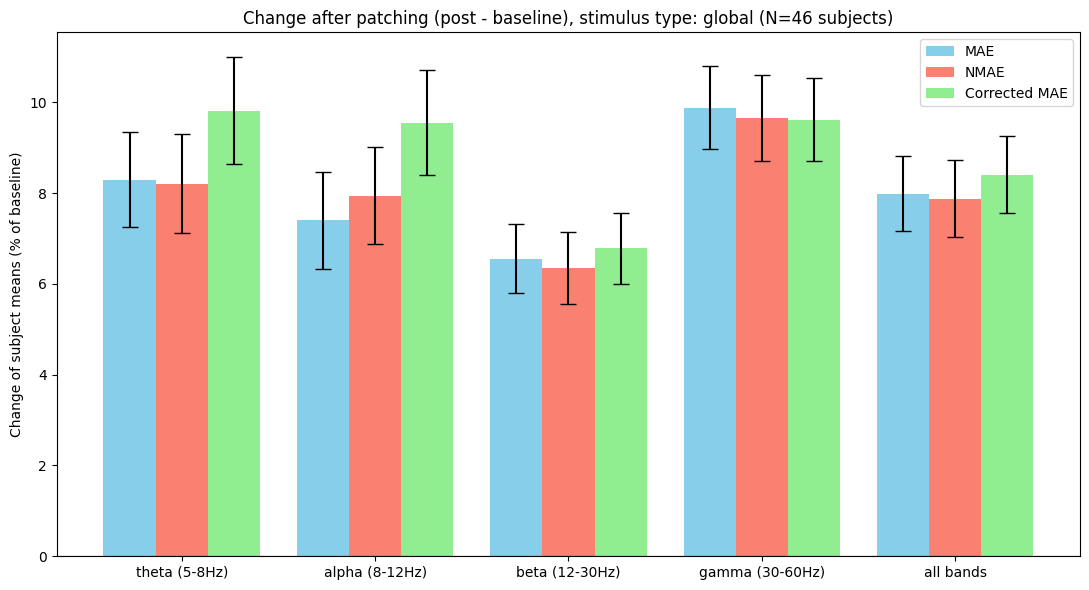

In [24]:
# raw change of the subject means per metric: mean ± SEM of the subject differences in % of the mean baseline, paired t-test
raw_changes = {}
for label, metric in metrics_to_compare.items():
    b_means, _ = data_processor.calc_subjectwise_metric_stats(baseline_merged, bands, metric)
    p_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, metric)
    subjects = [s for s in b_means if s in p_means]
    pre = np.array([[b_means[s][b] for b in band_keys] for s in subjects])
    post = np.array([[p_means[s][b] for b in band_keys] for s in subjects])
    scale = 100 / pre.mean(axis=0)
    raw_changes[label] = ((post - pre).mean(axis=0) * scale, sem(post - pre) * scale, ttest_rel(post, pre).pvalue)

print(f"{'band':16s}" + "".join(f" | {label + ' %':>17s} {'p':>6s}" for label in raw_changes))
for i, band in enumerate(band_keys):
    print(f"{band:16s}" + "".join(f" | {changes[i]:+17.2f} {ps[i]:6.3f}" for changes, _, ps in raw_changes.values()))

fig, ax = plt.subplots(figsize=(11, 6))
plotting.plot_grouped_bar(x_text=band_keys, width=0.27, means=[changes for changes, _, _ in raw_changes.values()],
                          sems=[sems for _, sems, _ in raw_changes.values()], labels=list(raw_changes.keys()),
                          title=f'Change after patching (post - baseline), stimulus type: {", ".join(conditions)}',
                          y_label="Change of subject means (% of baseline)", n_text=f"N={len(subjects)} subjects", ax=ax, fig=fig)
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison", default_name=f"mae_correction_difference_{an_suffix}_{excl_suffix}")
plt.show()


## Subject-level volatility adjustment
The baseline vs. post-patching comparison runs on subject means, so the volatility dependence is removed at that level:
for every band, one line is fitted on the subjects' metric change (post - baseline) against their volatility change.
The adjusted change of a subject is its change minus `slope * volatility change`, i.e. the change it would have without a volatility change.
The mean of the adjusted changes equals the intercept of the fit, which is tested for the adjusted effect.

### Subject changes vs. volatility change, before and after the adjustment
One point per subject, one figure per metric. Left: raw changes with the fitted line, showing how much the metric still depends on the volatility change.
Right: adjusted changes. The right line is flat by construction, so it illustrates the adjustment rather than validating it.

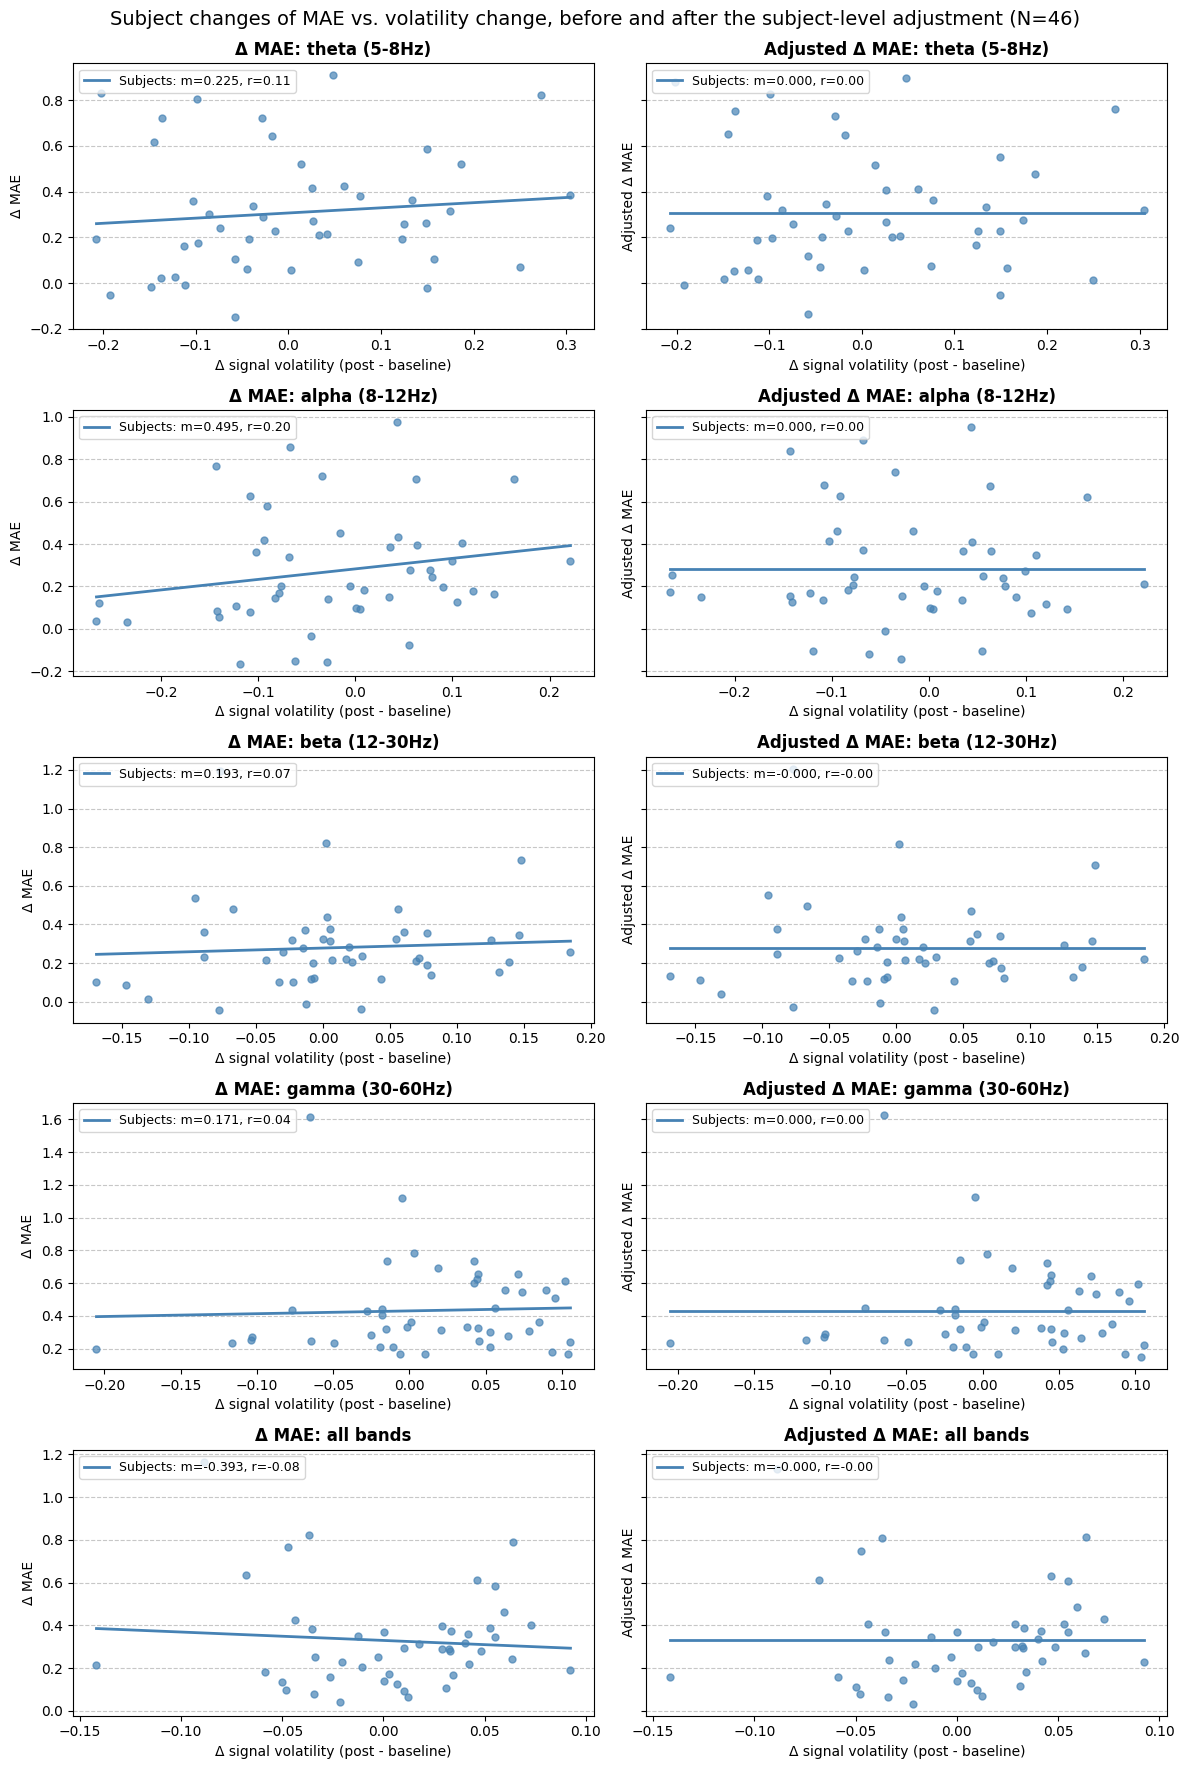

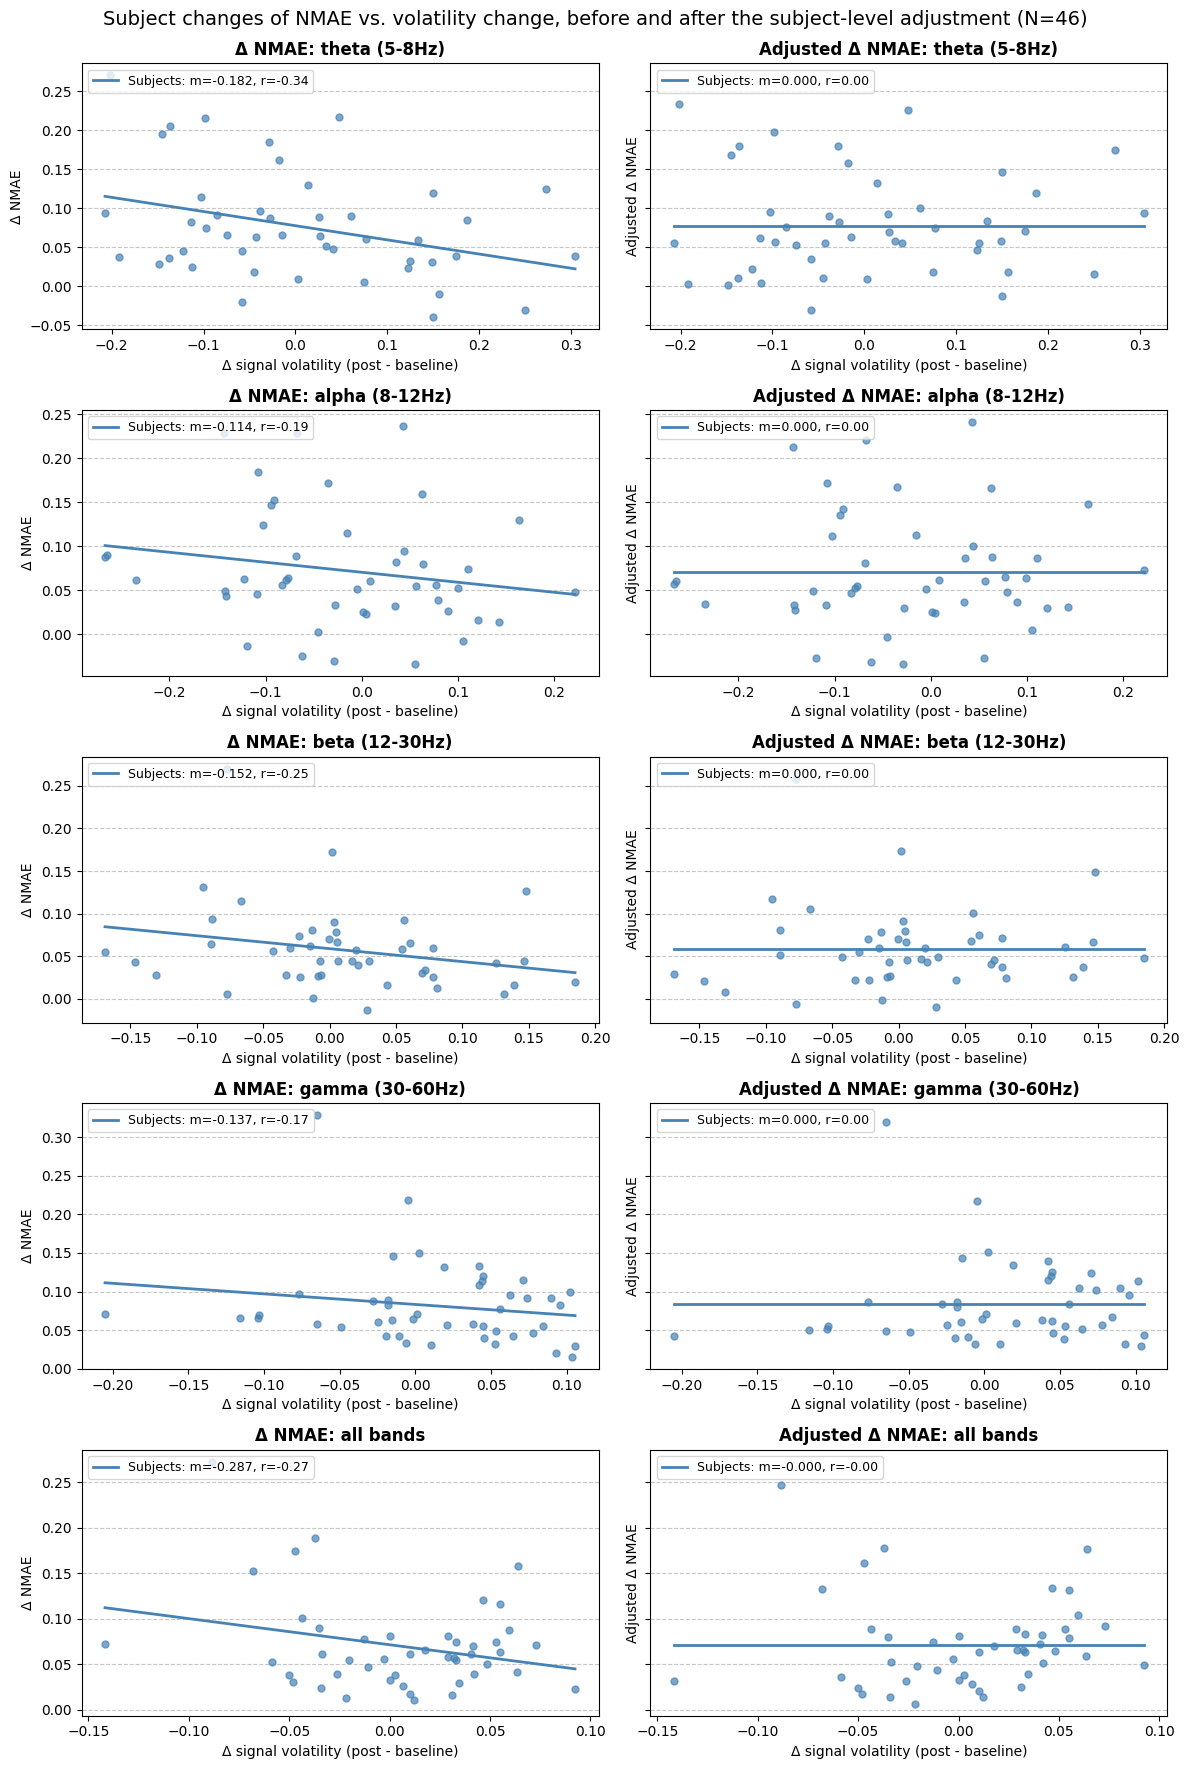

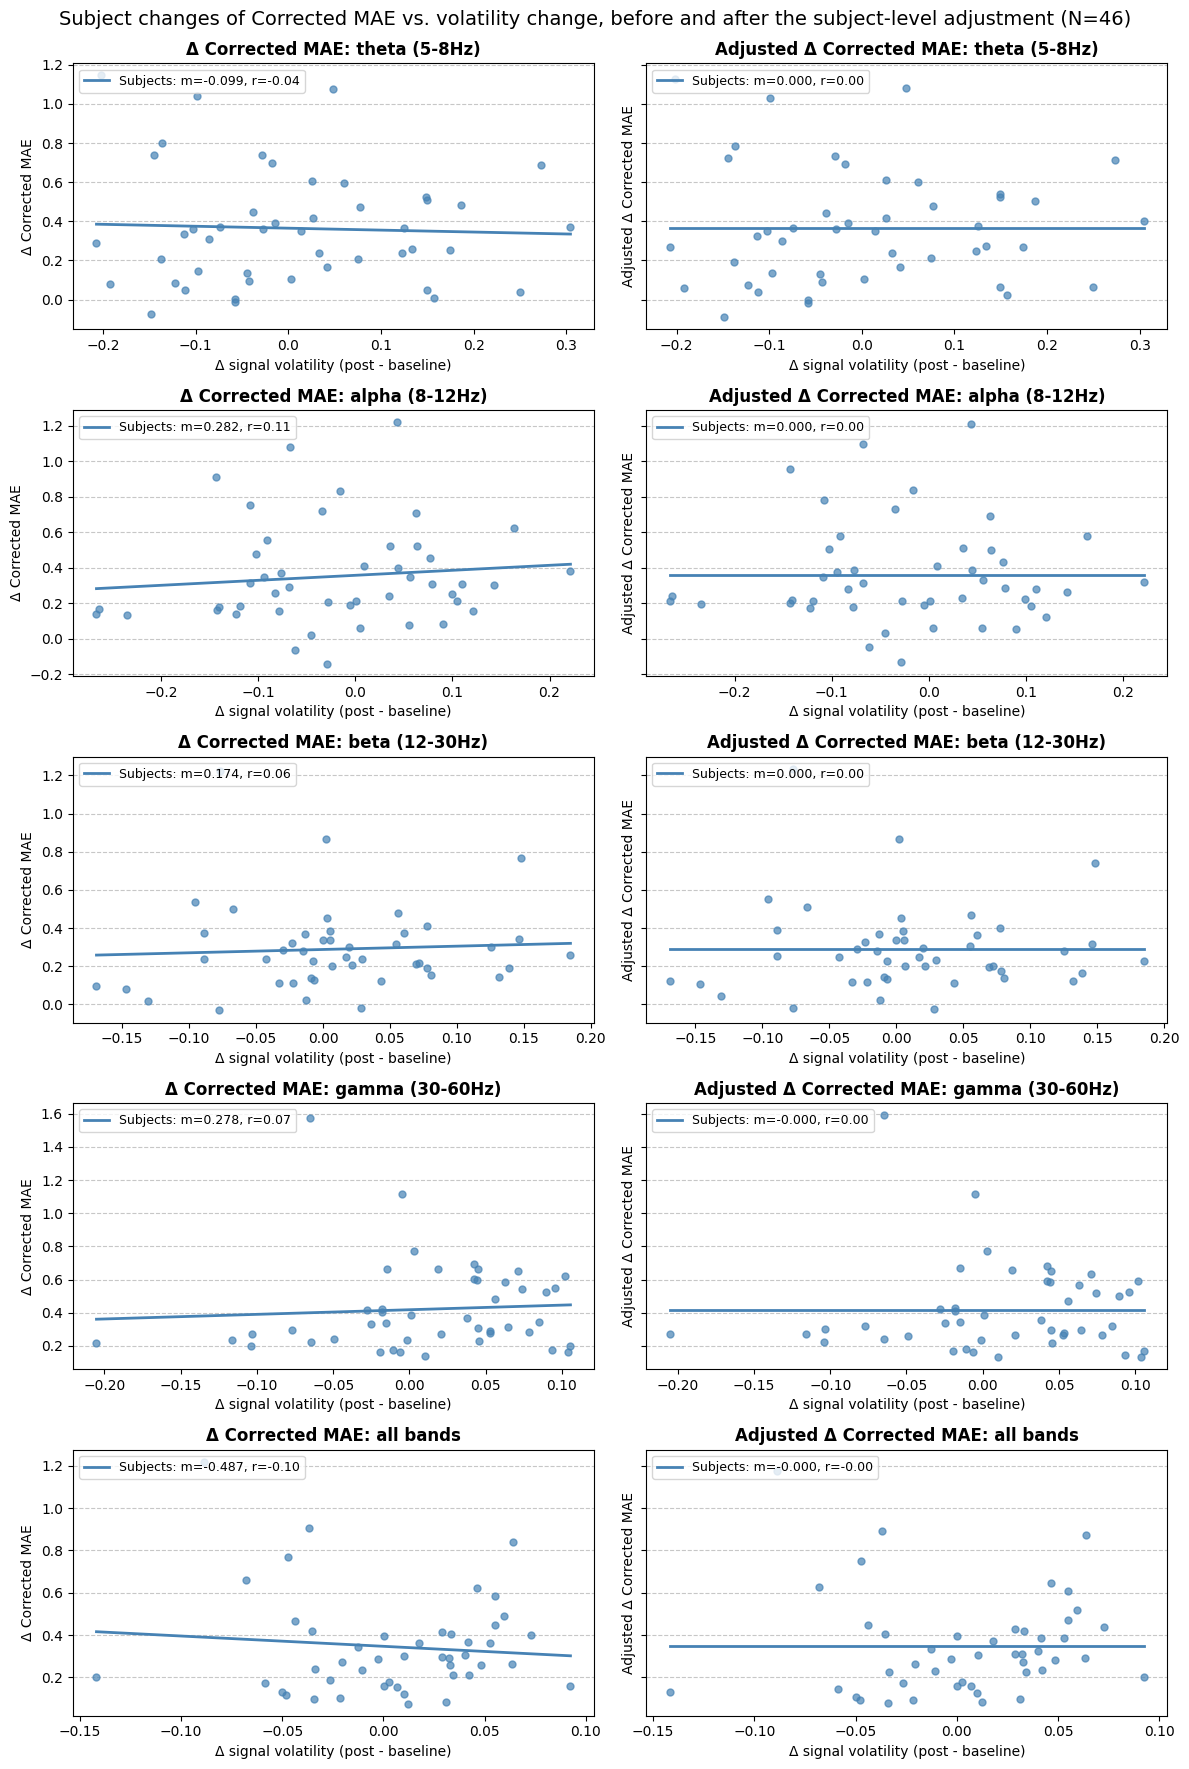

In [25]:
b_vol_means, _ = data_processor.calc_subjectwise_metric_stats(baseline_merged, bands, "signal_volatility")
p_vol_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, "signal_volatility")

for label, metric in metrics_to_compare.items():
    b_means, p_adjusted, _ = data_processor.calc_subject_adjusted_metric(baseline_merged, postpatch_merged, metric, bands)
    p_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, metric)
    subjects = list(b_means.keys())
    vol_changes = {b: [p_vol_means[s][b] - b_vol_means[s][b] for s in subjects] for b in band_keys}
    metric_changes = {b: [p_means[s][b] - b_means[s][b] for s in subjects] for b in band_keys}
    adjusted_changes = {b: [p_adjusted[s][b] - b_means[s][b] for s in subjects] for b in band_keys}

    plotting.session_correlation_plot(x_by_session={"Subjects": vol_changes},
                                      y_by_metric={f"Δ {label}": {"Subjects": metric_changes}, f"Adjusted Δ {label}": {"Subjects": adjusted_changes}},
                                      xlabel="Δ signal volatility (post - baseline)", point_size=25, point_alpha=0.7,
                                      title=f"Subject changes of {label} vs. volatility change, before and after the subject-level adjustment (N={len(subjects)})",
                                      save_dir=plot_root / "subject_adjustment", save_name=f"{metric}_subject_adjustment_{an_suffix}_{excl_suffix}")


### Change after patching before and after the subject-level adjustment
Left: raw change of the subject means (`raw_changes` from the cell "Change of MAE, NMAE and corrected MAE after patching" above). Right: change of the adjusted subject means (`calc_subject_adjusted_metric`).
Both are mean ± SEM of the subject differences in % of the mean baseline value of each metric, with a paired t-test. The adjusted test treats the fitted slope as known, so its p-values are marginally optimistic.
The three metrics disagree before the adjustment and agree after it. Note that adjusted MAE and adjusted corrected MAE are identical by construction: the trial-level correction subtracts a linear function of volatility, which the subject-level fit absorbs into its slope. The agreement with NMAE (a ratio, not a linear correction) is the independent check that the adjusted result doesn't depend on the choice of metric.

Raw
  band             |             MAE %      p |            NMAE %      p |   Corrected MAE %      p
  theta (5-8Hz)    |             +8.30  0.000 |             +8.21  0.000 |             +9.82  0.000
  alpha (8-12Hz)   |             +7.40  0.000 |             +7.94  0.000 |             +9.55  0.000
  beta (12-30Hz)   |             +6.56  0.000 |             +6.34  0.000 |             +6.79  0.000
  gamma (30-60Hz)  |             +9.88  0.000 |             +9.65  0.000 |             +9.62  0.000
  all bands        |             +7.99  0.000 |             +7.87  0.000 |             +8.41  0.000
Volatility-adjusted
  band             |             MAE %      p |            NMAE %      p |   Corrected MAE %      p
  theta (5-8Hz)    |             +8.26  0.000 |             +8.32  0.000 |             +9.84  0.000
  alpha (8-12Hz)   |             +7.67  0.000 |             +7.69  0.000 |             +9.71  0.000
  beta (12-30Hz)   |             +6.51  0.000 |             +6.51  0.000 |  

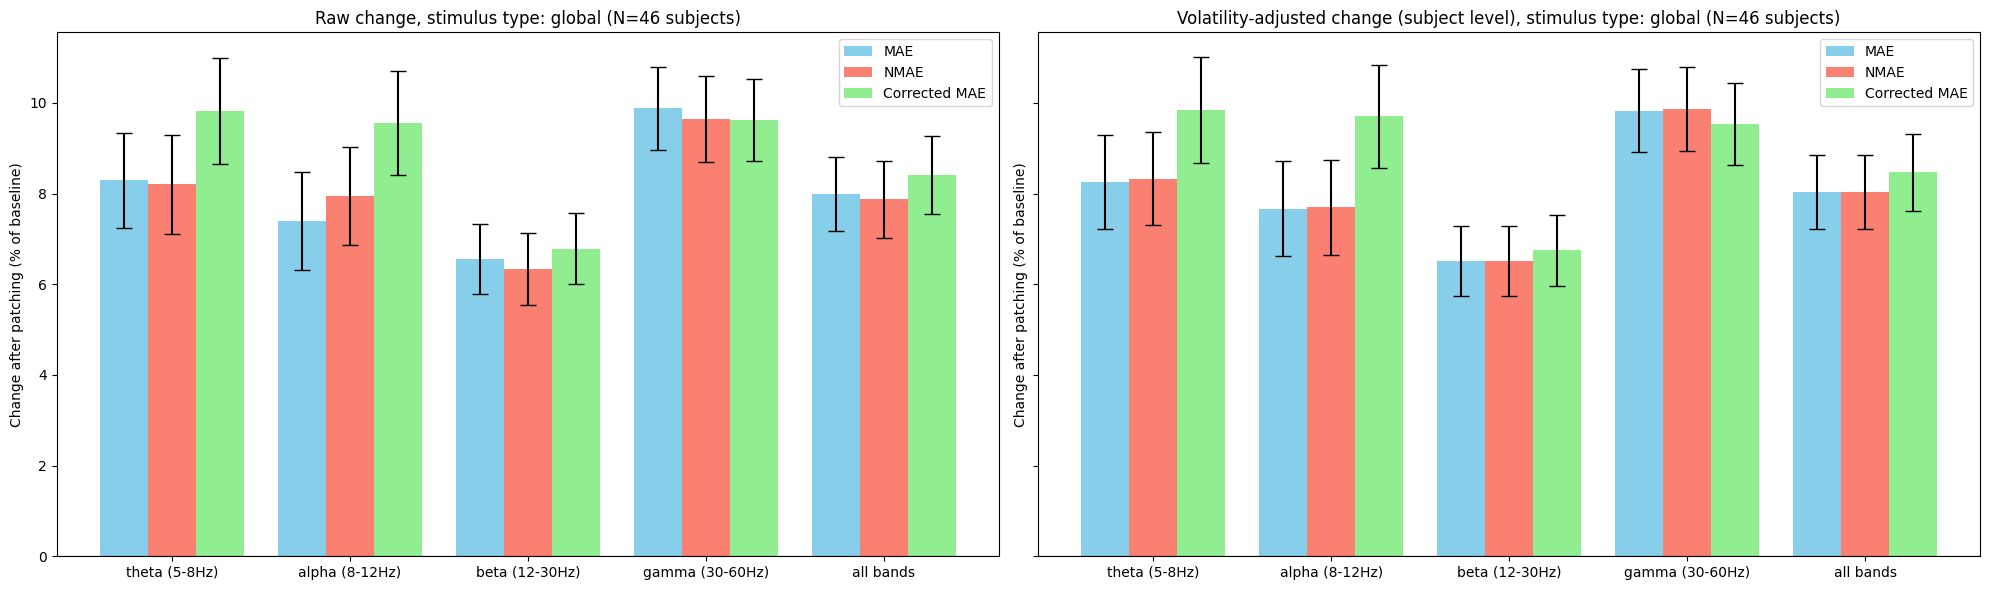

In [26]:
# adjusted change of the subject means per metric, same statistics as raw_changes
adjusted_changes_by_metric = {}
for label, metric in metrics_to_compare.items():
    b_means, p_adjusted, _ = data_processor.calc_subject_adjusted_metric(baseline_merged, postpatch_merged, metric, bands)
    subjects = list(b_means.keys())
    pre = np.array([[b_means[s][b] for b in band_keys] for s in subjects])
    post = np.array([[p_adjusted[s][b] for b in band_keys] for s in subjects])
    scale = 100 / pre.mean(axis=0)
    adjusted_changes_by_metric[label] = ((post - pre).mean(axis=0) * scale, sem(post - pre) * scale, ttest_rel(post, pre).pvalue)

for title, changes_by_metric in [("Raw", raw_changes), ("Volatility-adjusted", adjusted_changes_by_metric)]:
    print(title)
    print(f"  {'band':16s}" + "".join(f" | {label + ' %':>17s} {'p':>6s}" for label in changes_by_metric))
    for i, band in enumerate(band_keys):
        print(f"  {band:16s}" + "".join(f" | {changes[i]:+17.2f} {ps[i]:6.3f}" for changes, _, ps in changes_by_metric.values()))

fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
for ax, (title, changes_by_metric) in zip(axes, [("Raw change", raw_changes), ("Volatility-adjusted change (subject level)", adjusted_changes_by_metric)]):
    plotting.plot_grouped_bar(x_text=band_keys, width=0.27, means=[changes for changes, _, _ in changes_by_metric.values()],
                              sems=[sems for _, sems, _ in changes_by_metric.values()], labels=list(changes_by_metric.keys()),
                              title=f'{title}, stimulus type: {", ".join(conditions)}', y_label="Change after patching (% of baseline)",
                              n_text=f"N={len(subjects)} subjects", ax=ax, fig=fig)
    ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plotting.save_button(fig, save_dir=plot_root / "subject_adjustment", default_name=f"subject_adjustment_difference_{an_suffix}_{excl_suffix}")
plt.show()
